## What Makes a Play Store App Successful? __Installs, Reviews, Ratings, Price, Size and Updates__

**A CRISP-DM analysis using PySpark, Pandas, and Tableau Public**

This project starts from one headline question, *is there a relationship between an app's download volume (installs) and the number of reviews it receives?*, and extends it into a set of eight research questions  about what goes with app success: ratings by category, free vs. paid, size, price, update recency, audience, genre crowding, and a combined model. Each question has a stated hypothesis, a justified statistical method, an effect size with uncertainty.

**BLUF.** Installs and reviews are very strongly related (Spearman rho = 0.968, about 8.2x more reviews per 10x more installs), and the relationship holds in every category with at least 30 apps. Adding installs lifts the combined model's R² for reviews from 0.12 to 0.91, while rating, price, size and recency add only 0.02. Free apps reach far more users than paid apps (median 100,000 vs. 1,000 installs), larger and more recently updated apps tend to have more installs, and category and price type have only small effects on ratings. Figures are from the executed run on 9,659 apps and are associations, not causes.

## Business Understanding

Developers, product teams, and investors all try to read success from public signals. Reviews are the most visible one, but their meaning depends on how they relate to installs, ratings, price, and other app traits. This project tests those relationships carefully, and says clearly where the evidence is weak.

**Stakeholders**

| Stakeholder | Decision they face | How this analysis helps |
|---|---|---|
| App developers | Which category, price point, and size should we target? How many reviews should we expect? | Benchmarks for review rate, rating, size, and update cadence |
| Product managers | Should we charge for the app, prompt for reviews, or keep updating? | Evidence on price, size, and recency versus installs and ratings |
| Investors / publishers | Can public counts screen for traction? Which genres are crowded? | Reliability of reviews as a popularity proxy; genre concentration |
| Marketing teams | Which categories turn installs into reviews and high ratings? | Category comparisons with uncertainty |

**Primary question**

> **RQ1. Is there a relationship between installs and the number of Reviews an app receives, and how strong is it?**

**Research questions, hypotheses, and methods**

| ID | Research question | Hypothesis (H1) | Method | Effect size reported |
|---|---|---|---|---|
| RQ1 | Do apps with more installs get more reviews? How strong, and is it a category artifact? | Reviews rise with installs (positive monotonic relationship) | Spearman, Kendall, log-log regression, bootstrap CI, within-category checks, residuals | rho, slope, R² |
| RQ2 | Which categories have the best ratings? | Median ratings differ across categories | Kruskal-Wallis, bootstrap CI of medians | epsilon², CI overlap |
| RQ3 | Do paid apps earn higher ratings than free apps? | Paid apps are rated higher | Mann-Whitney U, bootstrap CI, category-adjusted comparison | Cliff's delta, median difference |
| RQ4 | How does app size relate to installs and ratings? | Larger apps have fewer installs | Spearman, size bands, category-adjusted correlation | rho |
| RQ5 | How does price relate to installs? | Higher price goes with fewer installs | Mann-Whitney, Spearman among paid apps, price bands | Cliff's delta, rho |
| RQ6 | How do installs and ratings vary with update recency? | Recently updated apps have more installs and higher ratings | Spearman, recency bands, share of fresh apps by install tier | rho |
| RQ7 | Which content-rating groups and genres dominate or are crowded? | Market is concentrated in a few genres and in "Everyone" | Shares, HHI concentration, apps vs. installs per app | HHI, saturation index |
| RQ8 | Which relationships survive when all factors are considered together? | Installs remain the dominant correlate of reviews after controls | OLS with category effects, standardized coefficients | R², delta R² |

## Data Understanding

**Source.** Sourced from the public Kaggle [Google Play Store Apps dataset](https://www.kaggle.com/datasets/yusufdelikkaya/google-play-store-apps-dataset), structured as one row per app listing scraped from the Google Play Store. At ~4 MB (~10,800 rows).

**Columns**

| Column | Meaning | Stored as | Keep? |
|---|---|---|---|
| `App` | App name | text | Yes (identifier) |
| `Category` | Store category | text | Yes |
| `Rating` | Average user rating | number | Yes |
| `Reviews` | Number of user reviews | text | **Yes (key variable)** |
| `Size` | App size, e.g. `19M`, `201k`, `Varies with device` | text | Yes, converted to MB |
| `Installs` | Install bucket, e.g. `10,000+` | text | **Yes (key variable)**, converted to a number |
| `Type` | Free or Paid | text | Yes |
| `Price` | Price, e.g. `$2.99` | text | Yes, converted to a number |
| `Content Rating` | Target audience | text | Yes |
| `Genres` | Genre(s), `;`-separated | text | Yes, primary genre extracted |
| `Last Updated` | Date of last update | text | Yes, parsed to a date |
| `Current Ver`, `Android Ver` | Version strings | text | **No**: messy free text with little analytic value here |

**Data issues expected**:
- Numeric information stored as text (`Installs`, `Price`, `Reviews`, `Size`).
- Missing values, most notably in `Rating`.
- Duplicate app listings.
- A malformed row whose values are shifted into the wrong columns.
- `Size` equal to `Varies with device` for many apps.
- Dates stored as text.

**Important property of `Installs`.** It is a *bucket* (a lower bound such as 10,000+), not an exact count. Many apps share a value, which creates ties in rank correlation and limits precision.

**Important property of `Rating`.** Apps with few reviews often have no rating. Rating analyses therefore describe apps that attracted enough reviews to be rated, which is a selection effect that is tested explicitly in RQ2.

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("./data/google_play_store_dataset.csv")

In [3]:
data.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
import os
import re
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# pyspark configuration
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark import StorageLevel

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# project configs
raw_path = "./data/google_play_store_dataset.csv"
clean_path = "./data/google_play_store_cleaned.csv"
image_path = "./images"
RANDOM_SEED = 42
MIN_N = 30
GREEN, BLUE, RED, GREY = "#01875f", "#4285f4", "#d93025", "#9aa0a6"

# collect research question answers here
ANSWERS = {}
os.makedirs(image_path, exist_ok=True)
os.makedirs(os.path.dirname(clean_path) or ".", exist_ok=True)

### Phase 1: Helper Functions & Data Loading

#### Spark session and execution model
- **Session:** `local[*]` uses all local cores. `spark.sql.shuffle.partitions = 8` avoids the default 200 tiny post-shuffle tasks on ~10k rows, and `spark.sql.ansi.enabled = false` makes invalid casts return `null` instead of failing, which the cleaning relies on. Arrow is disabled so `pyarrow` is not needed.
- **Lazy evaluation:** `filter`, `withColumn`, `select` and `groupBy` only build a plan; `count`, `show` and `collect` run it. Each `count()` in the cleaning audit is therefore a separate job, which is acceptable here because the data is small and the audit is the point.
- **Caching:** `raw_sdf` is cached after loading because profiling reads it repeatedly. `clean_sdf` is persisted (`MEMORY_AND_DISK`) because the outlier statistics, the Pandas hand-off and the Spark confirmation all reuse it. Both are released at the end of the notebook.
- **Spark vs. Pandas:** Spark does loading, profiling, type conversion and window-based de-duplication, the work that scales with data size. The cleaned set (~10k rows) fits in memory, so Pandas does date parsing, feature engineering, statistics and plotting, where its API is simpler.
- **Native expressions vs. UDFs:** a Python UDF runs in a separate Python worker, with serialization cost, and on PySpark 4.x that worker needs `pyarrow`. That was the failure in the first version. Native expressions run in the JVM and are visible to the optimizer, so the pipeline uses them; a UDF is kept only as an optional cross-check of the size parser.
- **Schema:** `inferSchema` is off, so all columns load as text. One malformed row would otherwise corrupt type inference; types are applied explicitly during cleaning.

#### Helper Functions

In [5]:
def get_spark(app_name: str = "PlayStoreAnalysis") -> SparkSession:
    """Create (or reuse) a local SparkSession tuned for a small dataset, with Arrow disabled."""
    return (
        SparkSession.builder.appName(app_name)
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.driver.memory", "2g")
        .config("spark.sql.ansi.enabled", "false")
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.sql.execution.arrow.pyspark.enabled", "false")    
        .config("spark.sql.execution.pythonUDF.arrow.enabled", "false")
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )

spark = get_spark()
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/15 05:43:50 WARN Utils: Your hostname, DESKTOP-7641MJU, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/15 05:43:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 05:43:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 05:43:54 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/15 05:43:54 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/15 05:43:54 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/11/15 05:43:54 WARN Utils

In [6]:
EXPECTED_COLUMNS = [
    "app", "category", "rating", "reviews", "size", "installs", "type",
    "price", "content_rating", "genres", "last_updated", "current_ver", "android_ver",
]

# regex parser
SIZE_PATTERN = r"^\s*([0-9]+(?:\.[0-9]+)?)\s*([kKmMgG])\s*$"
VALID_INSTALLS = r"^[0-9,]+\+?$"

def to_snake(name: str) -> str:
    """'Content Rating' -> 'content_rating' (consistent, Spark-friendly column names)."""
    return re.sub(r"\W+", "_", name.strip()).strip("_").lower()

def parse_size_mb(size):
    """Python reference: '19M' -> 19.0, '201k' -> 0.196, '1.2G' -> 1228.8. Anything else -> None."""
    if size is None:
        return None
    match = re.fullmatch(SIZE_PATTERN, str(size))
    if not match:
        return None
    value, unit = float(match.group(1)), match.group(2).lower()
    return value / 1024 if unit == "k" else value if unit == "m" else value * 1024

def size_mb_expr(col_name: str = "size"):
    """Native Spark column expression equivalent to parse_size_mb. Runs inside the JVM: no Python worker, no pyarrow."""
    num = F.regexp_extract(F.col(col_name), SIZE_PATTERN, 1)
    unit = F.lower(F.regexp_extract(F.col(col_name), SIZE_PATTERN, 2))
    value = num.cast("double")
    return (
        F.when(unit == "k", value / 1024)
         .when(unit == "m", value)
         .when(unit == "g", value * 1024)
         .otherwise(F.lit(None).cast("double"))
    )

def fmt_installs(n: int) -> str:
    """1000 -> '1K+', 5000000 -> '5M+', 500 -> '500+' (readable install bucket labels)."""
    n = int(n)
    if n >= 1_000_000_000: return f"{n // 1_000_000_000}B+"
    if n >= 1_000_000:     return f"{n // 1_000_000}M+"
    if n >= 1_000:         return f"{n // 1_000}K+"
    return f"{n}+"

def strength_label(r: float) -> str:
    """Plain-English label for the size of a correlation coefficient."""
    a = abs(r)
    if a < 0.2: return "negligible"
    if a < 0.4: return "weak"
    if a < 0.6: return "moderate"
    if a < 0.8: return "strong"
    return "very strong"

def to_pandas_safe(sdf) -> pd.DataFrame:
    """Spark -> Pandas WITHOUT Arrow/pyarrow: collect rows, build the frame, restore numeric dtypes."""
    out = pd.DataFrame([r.asDict() for r in sdf.collect()], columns=sdf.columns)
    numeric_types = ("double", "float", "bigint", "int", "smallint", "tinyint")
    for field in sdf.schema.fields:
        if field.dataType.simpleString() in numeric_types or field.dataType.simpleString().startswith("decimal"):
            out[field.name] = pd.to_numeric(out[field.name], errors="coerce")
    return out

def fmt_p(p: float) -> str:
    """Format a p-value; very small values are shown as '< 1e-300'."""
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"

def cliffs_delta(a, b) -> float:
    """Cliff's delta = P(a > b) - P(a < b), from the Mann-Whitney U statistic. Range -1..1, ties handled."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return float(2 * u / (len(a) * len(b)) - 1)

def delta_label(d: float) -> str:
    """Romano et al. thresholds for the magnitude of Cliff's delta."""
    a = abs(d)
    if a < 0.147: return "negligible"
    if a < 0.33:  return "small"
    if a < 0.474: return "medium"
    return "large"

def epsilon_squared(groups) -> tuple:
    """Kruskal-Wallis H, p-value and epsilon-squared effect size (share of rank variance explained by group)."""
    h, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    return float(h), float(p), float(max(0.0, (h - k + 1) / (n - k)))

def eps2_label(e: float) -> str:
    if e < 0.01: return "negligible"
    if e < 0.08: return "small"
    if e < 0.26: return "medium"
    return "large"

def bootstrap_median_ci(values, n_boot: int = 1000, seed: int = RANDOM_SEED):
    """95% bootstrap CI for a median."""
    rng = np.random.default_rng(seed)
    v = np.asarray(values, float)
    meds = np.median(rng.choice(v, size=(n_boot, len(v)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])

def bootstrap_median_diff_ci(a, b, n_boot: int = 2000, seed: int = RANDOM_SEED):
    """95% bootstrap CI for median(a) - median(b)."""
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    ma = np.median(rng.choice(a, size=(n_boot, len(a)), replace=True), axis=1)
    mb = np.median(rng.choice(b, size=(n_boot, len(b)), replace=True), axis=1)
    return np.percentile(ma - mb, [2.5, 97.5])

def hhi(counts) -> float:
    """Herfindahl-Hirschman index on shares (0..1). 1/n = perfectly even, 1 = one group holds everything."""
    c = np.asarray(counts, float)
    s = c / c.sum()
    return float((s ** 2).sum())

def ols_fit(df: pd.DataFrame, y: str, numeric: list, categorical: str = None) -> dict:
    """OLS with standardized numeric predictors and optional category dummies (numpy only, no extra packages)."""
    cols = [y] + numeric + ([categorical] if categorical else [])
    d = df[cols].dropna()
    yv = d[y].to_numpy(float)
    yz = (yv - yv.mean()) / yv.std(ddof=0)
    blocks = [np.ones((len(d), 1))]
    if numeric:
        X = d[numeric].astype(float)
        blocks.append(((X - X.mean()) / X.std(ddof=0)).to_numpy())
    if categorical:
        blocks.append(pd.get_dummies(d[categorical], drop_first=True, dtype=float).to_numpy())
    A = np.hstack(blocks)
    beta, *_ = np.linalg.lstsq(A, yz, rcond=None)
    resid = yz - A @ beta
    r2 = 1 - float(resid @ resid) / float(yz @ yz)
    coefs = pd.Series(beta[1:1 + len(numeric)], index=numeric, dtype=float)
    return {"r2": r2, "coefs": coefs, "n": len(d)}

In [7]:
# helper tests
assert to_snake("Content Rating") == "content_rating"
assert parse_size_mb("19M") == 19.0 and parse_size_mb("1G") == 1024.0 and parse_size_mb("1.5M") == 1.5
assert abs(parse_size_mb("201k") - 201 / 1024) < 1e-9
assert parse_size_mb("Varies with device") is None and parse_size_mb(None) is None
assert fmt_installs(500) == "500+" and fmt_installs(10_000) == "10K+" and fmt_installs(5_000_000) == "5M+"
assert strength_label(0.9) == "very strong" and strength_label(-0.1) == "negligible"
assert cliffs_delta([1, 2, 3], [0]) == 1.0 and cliffs_delta([0], [1, 2, 3]) == -1.0
assert abs(cliffs_delta([1, 2, 3], [1, 2, 3])) < 1e-12
assert delta_label(0.1) == "negligible" and delta_label(-0.5) == "large"
assert abs(hhi([1, 1, 1, 1]) - 0.25) < 1e-12 and hhi([5]) == 1.0
assert abs(ols_fit(pd.DataFrame({"y": [1., 2, 3, 4, 5], "x": [2., 4, 6, 8, 10]}), "y", ["x"])["r2"] - 1) < 1e-9
print("helper tests passed")

helper tests passed


In [8]:
def native_vs_reference(samples) -> bool:
    test = spark.createDataFrame([(s,) for s in samples], "size string")
    got = to_pandas_safe(test.select("size", size_mb_expr("size").alias("native")))
    for s, native in zip(samples, got["native"]):
        expected = parse_size_mb(s)
        same = (expected is None and pd.isna(native)) or (expected is not None and abs(expected - native) < 1e-9)
        assert same, f"Mismatch for {s!r}: native={native}, reference={expected}"
    return True

def optional_udf_crosscheck(samples) -> str:
    try:
        try:
            udf = F.udf(parse_size_mb, DoubleType(), useArrow=False)    
        except TypeError:
            udf = F.udf(parse_size_mb, DoubleType())
        test = spark.createDataFrame([(s,) for s in samples], "size string")
        out = to_pandas_safe(test.select(size_mb_expr("size").alias("native"), udf("size").alias("udf")))
        ok = np.allclose(out["native"].fillna(-1), out["udf"].fillna(-1))
        return "UDF cross-check passed" if ok else "UDF cross-check DISAGREES with native expression"
    except Exception as exc:                                        
        return f"UDF cross-check skipped (Python worker unavailable: {type(exc).__name__}). Pipeline unaffected."

In [9]:
# native spark size parser vs python reference (and an optional udf check)
SIZE_SAMPLES = ["19M", "201k", "1.5G", "Varies with device", "8.5M", "1,000+", "", None]
print("native expression matches reference:", native_vs_reference(SIZE_SAMPLES))
print(optional_udf_crosscheck(SIZE_SAMPLES))

native expression matches reference: True
UDF cross-check passed


#### Data Loading

In [10]:
def load_raw(path: str):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Dataset not found at '{path}'. Put the CSV there or change raw_path."
        )
    df = (
        spark.read.option("header", True)
        .option("inferSchema", False)       
        .option("multiLine", True)
        .option("quote", '"').option("escape", '"')
        .option("nullValue", "NaN")       
        .csv(path)
    )
    return df.toDF(*[to_snake(c) for c in df.columns])

In [11]:
try:
    raw_sdf = load_raw(raw_path)
    raw_sdf.cache()                         
    n_rows = raw_sdf.count()
except Exception as exc:
    raise RuntimeError(f"Could not load the dataset: {exc}") from exc

In [12]:
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_sdf.columns]
assert n_rows > 0, "loaded dataframe is empty"
assert not missing_cols, f"missing expected columns: {missing_cols}"

print(f"rows: {n_rows:,} | columns: {len(raw_sdf.columns)}")
raw_sdf.printSchema()
raw_sdf.show(5, truncate=40)

rows: 10,841 | columns: 13
root
 |-- app: string (nullable = true)
 |-- category: string (nullable = true)
 |-- rating: string (nullable = true)
 |-- reviews: string (nullable = true)
 |-- size: string (nullable = true)
 |-- installs: string (nullable = true)
 |-- type: string (nullable = true)
 |-- price: string (nullable = true)
 |-- content_rating: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- last_updated: string (nullable = true)
 |-- current_ver: string (nullable = true)
 |-- android_ver: string (nullable = true)

+----------------------------------------+--------------+------+-------+----+-----------+----+-----+--------------+-------------------------+----------------+------------------+------------+
|                                     app|      category|rating|reviews|size|   installs|type|price|content_rating|                   genres|    last_updated|       current_ver| android_ver|
+----------------------------------------+--------------+------+------

### Phase 3: Exploratory Data Analysis

In [13]:
# descriptive statistics
numeric_view = raw_sdf.select(
    F.col("rating").cast("double").alias("rating"),
    F.col("reviews").cast("double").alias("reviews"),
)
numeric_view.summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").show()
# all columns (string columns report count, min and max only)
raw_sdf.describe().show(truncate=18)
raw_sdf.select("size", "installs", "price", "last_updated").show()

+-------+------------------+------------------+
|summary|            rating|           reviews|
+-------+------------------+------------------+
|  count|              9367|             10840|
|   mean| 4.193338315362448|444152.89603321033|
| stddev|0.5374313031477593|2927760.6038856646|
|    min|               1.0|               0.0|
|    25%|               4.0|              38.0|
|    50%|               4.3|            2093.0|
|    75%|               4.5|           54520.0|
|    max|              19.0|       7.8158306E7|
+-------+------------------+------------------+

+-------+------------------+--------+------------------+------------------+------------------+--------+-----+--------+---------------+------+-----------------+------------------+------------------+
|summary|               app|category|            rating|           reviews|              size|installs| type|   price| content_rating|genres|     last_updated|       current_ver|       android_ver|
+-------+------------------

In [14]:
# missing values
null_counts = to_pandas_safe(raw_sdf.select(
    [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in raw_sdf.columns]
)).T.rename(columns={0: "null_count"})
null_counts["null_pct"] = null_counts["null_count"] / n_rows * 100
display(null_counts.sort_values("null_count", ascending=False))

# duplicates
full_dupes = n_rows - raw_sdf.dropDuplicates().count()
distinct_apps = raw_sdf.select("app").distinct().count()
print(f"full duplicate rows: {full_dupes:,} | distinct apps: {distinct_apps:,}")

# unique value counts per column
distinct_counts = to_pandas_safe(raw_sdf.agg(
    *[F.countDistinct(c).alias(c) for c in raw_sdf.columns]
)).T.rename(columns={0: "distinct_values"})
display(distinct_counts)

,null_count,null_pct
rating,1474,13.597
current_ver,8,0.074
android_ver,3,0.028
content_rating,1,0.009
type,1,0.009
size,0,0.000
reviews,0,0.000
category,0,0.000
app,0,0.000
price,0,0.000


full duplicate rows: 483 | distinct apps: 9,660


,distinct_values
app,9660
category,34
rating,40
reviews,6002
size,462
installs,22
type,3
price,93
content_rating,6
genres,120


In [15]:
# categorical columns distribution
for col in ["type", "content_rating", "installs"]:
    raw_sdf.groupBy(col).count().orderBy(F.desc("count")).show(25, truncate=40)

raw_sdf.groupBy("category").count().orderBy(F.desc("count")).show(15, truncate=40)

+----+-----+
|type|count|
+----+-----+
|Free|10039|
|Paid|  800|
|NULL|    1|
|   0|    1|
+----+-----+

+---------------+-----+
| content_rating|count|
+---------------+-----+
|       Everyone| 8714|
|           Teen| 1208|
|     Mature 17+|  499|
|   Everyone 10+|  414|
|Adults only 18+|    3|
|        Unrated|    2|
|           NULL|    1|
+---------------+-----+

+--------------+-----+
|      installs|count|
+--------------+-----+
|    1,000,000+| 1579|
|   10,000,000+| 1252|
|      100,000+| 1169|
|       10,000+| 1054|
|        1,000+|  907|
|    5,000,000+|  752|
|          100+|  719|
|      500,000+|  539|
|       50,000+|  479|
|        5,000+|  477|
|  100,000,000+|  409|
|           10+|  386|
|          500+|  330|
|   50,000,000+|  289|
|           50+|  205|
|            5+|   82|
|  500,000,000+|   72|
|            1+|   67|
|1,000,000,000+|   58|
|            0+|   14|
|             0|    1|
|          Free|    1|
+--------------+-----+

+------------------+-----+
|   

In [16]:
# anomalies: rows that do not look like valid app records
is_bad_installs = ~F.coalesce(F.col("installs").rlike(VALID_INSTALLS), F.lit(False))
is_bad_rating = F.col("rating").cast("double") > 5

bad_rows = raw_sdf.filter(is_bad_installs | is_bad_rating)
n_bad = bad_rows.count()
bad_rows.show(truncate=30)

n_varies = raw_sdf.filter(F.col("size") == "Varies with device").count()
n_dollar = raw_sdf.filter(F.col("price").contains("$")).count()
print(f"malformed rows: {n_bad} | duplicate rows: {full_dupes:,} | repeated app rows: {n_rows - distinct_apps:,}")
print(f"'Varies with device' sizes: {n_varies:,} | '$' prices: {n_dollar:,}")

+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|                           app|category|rating|reviews|  size|installs|type|   price|content_rating|           genres|last_updated|current_ver|android_ver|
+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|Life Made WI-Fi Touchscreen...|     1.9|    19|   3.0M|1,000+|    Free|   0|Everyone|          NULL|February 11, 2018|      1.0.19| 4.0 and up|       NULL|
+------------------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+

malformed rows: 1 | duplicate rows: 483 | repeated app rows: 1,181
'Varies with device' sizes: 1,695 | '$' prices: 800


In [17]:
# type mismatches: values that fail the conversion they need
price_ok = F.coalesce(F.col("price").rlike(r"^\$?[0-9]+(\.[0-9]+)?$"), F.lit(False))
type_checks = {
    "rating_not_numeric":      F.col("rating").isNotNull() & F.col("rating").cast("double").isNull(),
    "reviews_not_integer":     F.col("reviews").isNotNull() & F.col("reviews").cast("long").isNull(),
    "installs_invalid_bucket": is_bad_installs,
    "price_not_a_price":       ~price_ok,
    "size_unrecognised":       ~(F.coalesce(F.col("size").rlike(SIZE_PATTERN), F.lit(False)) | (F.col("size") == "Varies with device")),
    "type_not_free_or_paid":   ~F.coalesce(F.col("type").isin("Free", "Paid"), F.lit(False)),
}
type_mismatch = to_pandas_safe(raw_sdf.select(
    [F.sum(cond.cast("int")).alias(name) for name, cond in type_checks.items()])).T.rename(columns={0: "rows_failing"})
display(type_mismatch)

,rows_failing
rating_not_numeric,0
reviews_not_integer,1
installs_invalid_bucket,1
price_not_a_price,1
size_unrecognised,1
type_not_free_or_paid,2


In [18]:
# prioritized issue log (counts come from the data)
n_null_rating = raw_sdf.filter(F.col("rating").isNull()).count()
n_null_type = raw_sdf.filter(F.col("type").isNull()).count()
n_multi_genre = raw_sdf.filter(F.col("genres").contains(";")).count()

issues = pd.DataFrame([
    ("High",   "malformed row (shifted columns, invalid installs)", n_bad, "remove rows whose installs is not a valid bucket"),
    ("High",   "duplicate app listings", n_rows - distinct_apps, "one row per app: most reviews, then most installs (window function)"),
    ("High",   "installs, reviews stored as text", n_rows, "strip ',' and '+', cast to long"),
    ("High",   "price stored as text", n_dollar, "strip '$', cast to double"),
    ("Medium", "size in mixed units / 'Varies with device'", n_rows, "native spark expression to MB; 'Varies' stays null and is flagged"),
    ("Medium", "missing rating", n_null_rating, "keep null (no imputation); test missingness against popularity (RQ2)"),
    ("Medium", "missing type", n_null_type, "derive from price"),
    ("Medium", "last_updated stored as text", n_rows, "parse to date in pandas"),
    ("Low",    "current_ver / android_ver free text", n_rows, "drop"),
    ("Low",    "multi-valued genres", n_multi_genre, "keep first genre"),
], columns=["priority", "issue", "rows_affected", "planned_fix"])
display(issues)

,priority,issue,rows_affected,planned_fix
0,High,"malformed row (shifted columns, invalid installs)",1,remove rows whose installs is not a valid bucket
1,High,duplicate app listings,1181,"one row per app: most reviews, then most insta..."
2,High,"installs, reviews stored as text",10841,"strip ',' and '+', cast to long"
3,High,price stored as text,800,"strip '$', cast to double"
4,Medium,size in mixed units / 'Varies with device',10841,native spark expression to MB; 'Varies' stays ...
5,Medium,missing rating,1474,keep null (no imputation); test missingness ag...
6,Medium,missing type,1,derive from price
7,Medium,last_updated stored as text,10841,parse to date in pandas
8,Low,current_ver / android_ver free text,10841,drop
9,Low,multi-valued genres,498,keep first genre


**Assumptions**
1. A row with an invalid `Installs` value is malformed and removed; it cannot be repaired reliably.
2. For repeated apps, the row with the most reviews is kept.
3. Missing `Rating` is not imputed. Rating statistics use rated apps only, and RQ2 tests how those apps differ from unrated ones.
4. `Installs` is the lower bound of its bucket (`10,000+` becomes 10,000).
5. Logs use `log10(x + 1)` so zero-review apps stay in; one robustness check drops them.
6. Tests are rank-based or bootstrap because installs, reviews and prices are heavily skewed. Effect sizes are reported alongside p-values because with ~10k apps almost any difference is significant.

## Data Preparation

### Phase 4: Data Cleaning

In [19]:
def clean_with_spark(df):
    """bulk cleaning in spark; returns (clean_df, audit of row counts after each step)"""
    audit = {"rows_in": df.count()}

    # malformed rows: installs must look like '10,000+'
    step = df.filter(F.coalesce(F.col("installs").rlike(VALID_INSTALLS), F.lit(False)))
    audit["after_malformed_removal"] = step.count()

    # types (native expressions, no python udf)
    step = (
        step
        .withColumn("rating", F.col("rating").cast("double"))
        .withColumn("reviews", F.col("reviews").cast("long"))
        .withColumn("installs", F.regexp_replace("installs", r"[,+]", "").cast("long"))
        .withColumn("price", F.regexp_replace("price", r"\$", "").cast("double"))
        .withColumn("size_mb", size_mb_expr("size"))
        .withColumn(
            "type",
            F.when(F.col("type").isin("Free", "Paid"), F.col("type"))
             .when(F.col("price") > 0, F.lit("Paid"))
             .otherwise(F.lit("Free")),
        )
    )

    step = step.dropna(subset=["app", "category", "installs", "reviews", "price"])
    audit["after_required_fields"] = step.count()

    # ratings must be 1-5 when present; nulls are kept
    step = step.filter(F.col("rating").isNull() | F.col("rating").between(1.0, 5.0))
    audit["after_rating_range"] = step.count()

    # window 1: one row per app (most reviews, then most installs)
    w_dedup = Window.partitionBy("app").orderBy(
        F.col("reviews").desc_nulls_last(), F.col("installs").desc_nulls_last()
    )
    step = step.withColumn("rn", F.row_number().over(w_dedup)).filter(F.col("rn") == 1).drop("rn")
    audit["after_deduplication"] = step.count()

    # window 2: install percentile within category
    w_cat = Window.partitionBy("category").orderBy("installs")
    step = step.withColumn("installs_pct_rank_in_category", F.percent_rank().over(w_cat))
    return step, audit

In [20]:
try:
    clean_sdf, audit = clean_with_spark(raw_sdf)
    clean_sdf.persist(StorageLevel.MEMORY_AND_DISK)
    n_clean = clean_sdf.count()
except Exception as exc:
    raise RuntimeError(f"spark cleaning failed: {exc}") from exc

audit_df = pd.DataFrame({"step": list(audit), "rows": list(audit.values())})
audit_df["rows_removed_in_step"] = (audit_df["rows"].shift(1) - audit_df["rows"]).fillna(0).astype(int)
display(audit_df)
print(f"rows kept: {n_clean:,} of {n_rows:,} ({n_clean / n_rows:.1%})")
clean_sdf.select("app", "category", "rating", "reviews", "size_mb", "installs", "type", "price").show(5, truncate=30)

,step,rows,rows_removed_in_step
0,rows_in,10841,0
1,after_malformed_removal,10840,1
2,after_required_fields,10840,0
3,after_rating_range,10840,0
4,after_deduplication,9659,1181


rows kept: 9,659 of 10,841 (89.1%)
+------------------------------+-------------------+------+-------+-------+--------+----+-----+
|                           app|           category|rating|reviews|size_mb|installs|type|price|
+------------------------------+-------------------+------+-------+-------+--------+----+-----+
| Pistolet CZ-70 CZ-50 expliqué|BOOKS_AND_REFERENCE|  NULL|      0|   17.0|       1|Paid| 5.99|
|        BibleRead En Cy Zh Yue|BOOKS_AND_REFERENCE|  NULL|      0|   12.0|       5|Free|  0.0|
|CZ-38 (vz 38) pistol explained|BOOKS_AND_REFERENCE|  NULL|      0|   13.0|       5|Paid| 5.99|
|                       CZ-Help|BOOKS_AND_REFERENCE|   5.0|      2|    1.4|       5|Free|  0.0|
|                        EW PDF|BOOKS_AND_REFERENCE|  NULL|      0|    8.7|       5|Free|  0.0|
+------------------------------+-------------------+------+-------+-------+--------+----+-----+
only showing top 5 rows


In [21]:
# physical plan: the Window nodes come from row_number / percent_rank, each preceded by a shuffle (Exchange)
clean_sdf.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- InMemoryTableScan [app#20, category#21, rating#9622, reviews#9623L, size#24, installs#9624L, type#9627, price#9625, content_rating#28, genres#29, last_updated#30, current_ver#31, android_ver#32, size_mb#9626, installs_pct_rank_in_category#10659]
      +- InMemoryRelation [app#20, category#21, rating#9622, reviews#9623L, size#24, installs#9624L, type#9627, price#9625, content_rating#28, genres#29, last_updated#30, current_ver#31, android_ver#32, size_mb#9626, installs_pct_rank_in_category#10659], StorageLevel(disk, memory, 1 replicas)
            +- AdaptiveSparkPlan isFinalPlan=true
               +- == Final Plan ==
                  ResultQueryStage 3
                  +- Window [percent_rank(installs#9624L) windowspecdefinition(category#21, installs#9624L ASC NULLS FIRST, specifiedwindowframe(RowFrame, unboundedpreceding$(), currentrow$())) AS installs_pct_rank_in_category#10659], [category#21], [installs#9624L ASC NULLS FIR

In [22]:
# spark-side outlier fences (iqr) and a naive raw-scale correlation as a baseline
for col in ["reviews", "installs"]:
    q1, q3 = clean_sdf.approxQuantile(col, [0.25, 0.75], 0.01)
    upper = q3 + 1.5 * (q3 - q1)
    n_out = clean_sdf.filter(F.col(col) > upper).count()
    print(f"{col:9s} Q1={q1:>12,.0f}  Q3={q3:>12,.0f}  upper fence={upper:>14,.0f}  above fence: {n_out:,} ({n_out / n_clean:.1%})")
print("spark pearson, raw installs vs raw reviews:", round(clean_sdf.stat.corr("installs", "reviews"), 4))

reviews   Q1=          25  Q3=      27,104  upper fence=        67,722  above fence: 1,724 (17.8%)
installs  Q1=       1,000  Q3=   1,000,000  upper fence=     2,498,500  above fence: 1,981 (20.5%)
spark pearson, raw installs vs raw reviews: 0.6251


In [23]:
# hand-off to pandas without arrow
pdf = to_pandas_safe(clean_sdf)
pdf.shape

(9659, 15)

In [24]:
def engineer_features(pdf: pd.DataFrame) -> pd.DataFrame:
    """pandas stage: dates, genre, log features, ordered buckets and analysis bands"""
    df = pdf.copy()

    df["last_updated"] = pd.to_datetime(df["last_updated"], format="%B %d, %Y", errors="coerce")
    snapshot_date = df["last_updated"].max()
    df["days_since_update"] = (snapshot_date - df["last_updated"]).dt.days

    df["category"] = df["category"].str.replace("_", " ").str.title().str.replace(" And ", " & ")
    df["primary_genre"] = df["genres"].str.split(";").str[0].str.strip()

    df["is_paid"] = df["type"].eq("Paid")
    df["size_missing"] = df["size_mb"].isna()
    df["has_rating"] = df["rating"].notna()

    df["log10_installs"] = np.log10(df["installs"] + 1)
    df["log10_reviews"] = np.log10(df["reviews"] + 1)
    df["log10_price1"] = np.log10(df["price"] + 1)
    df["log10_size_mb"] = np.log10(df["size_mb"])
    df["reviews_per_1k_installs"] = np.where(df["installs"] > 0, df["reviews"] / df["installs"] * 1000, np.nan)

    labels_in_order = [fmt_installs(v) for v in sorted(df["installs"].unique())]
    df["installs_bucket"] = pd.Categorical(df["installs"].map(fmt_installs), categories=labels_in_order, ordered=True)
    df["installs_bucket_rank"] = df["installs"].rank(method="dense").astype(int)

    size_labels = ["<5 MB", "5-15 MB", "15-30 MB", "30-60 MB", "60+ MB"]
    df["size_band"] = pd.cut(df["size_mb"], bins=[0, 5, 15, 30, 60, np.inf], labels=size_labels, right=False)
    df["size_band"] = df["size_band"].cat.add_categories("Varies with device").fillna("Varies with device")

    price_labels = ["Free", "$0.01-0.99", "$1-2.99", "$3-9.99", "$10+"]
    df["price_band"] = pd.Categorical(
        np.select([df["price"] == 0, df["price"] < 1, df["price"] < 3, df["price"] < 10], price_labels[:4],
                  default=price_labels[4]),
        categories=price_labels, ordered=True)

    recency_labels = ["0-30 days", "31-90 days", "91-365 days", "1-2 years", "2+ years"]
    df["recency_band"] = pd.cut(df["days_since_update"], bins=[-1, 30, 90, 365, 730, np.inf], labels=recency_labels)

    df["install_tier"] = pd.Categorical(
        np.select([df["installs"] < 10_000, df["installs"] < 1_000_000], ["<10K", "10K-1M"], default="1M+"),
        categories=["<10K", "10K-1M", "1M+"], ordered=True)

    return df.drop(columns=["size", "current_ver", "android_ver"], errors="ignore")

clean_df = engineer_features(pdf)
print("shape:", clean_df.shape)
clean_df.head()

shape: (9659, 28)


,app,category,rating,reviews,installs,type,price,content_rating,genres,last_updated,size_mb,installs_pct_rank_in_category,days_since_update,primary_genre,is_paid,size_missing,has_rating,log10_installs,log10_reviews,log10_price1,log10_size_mb,reviews_per_1k_installs,installs_bucket,installs_bucket_rank,size_band,price_band,recency_band,install_tier
0,Pistolet CZ-70 CZ-50 expliqué,Books & Reference,NaN,0,1,Paid,5.990,Everyone,Books & Reference,2016-11-01,17.000,0.000,645,Books & Reference,True,False,False,0.301,0.000,0.844,1.230,0.000,1+,2,15-30 MB,$3-9.99,1-2 years,<10K
1,BibleRead En Cy Zh Yue,Books & Reference,NaN,0,5,Free,0.000,Everyone,Books & Reference,2018-05-17,12.000,0.005,83,Books & Reference,False,False,False,0.778,0.000,0.000,1.079,0.000,5+,3,5-15 MB,Free,31-90 days,<10K
2,CZ-38 (vz 38) pistol explained,Books & Reference,NaN,0,5,Paid,5.990,Everyone,Books & Reference,2017-08-10,13.000,0.005,363,Books & Reference,True,False,False,0.778,0.000,0.844,1.114,0.000,5+,3,5-15 MB,$3-9.99,91-365 days,<10K
3,CZ-Help,Books & Reference,5.000,2,5,Free,0.000,Everyone,Books & Reference,2018-07-13,1.400,0.005,26,Books & Reference,False,False,True,0.778,0.477,0.000,0.146,400.000,5+,3,<5 MB,Free,0-30 days,<10K
4,EW PDF,Books & Reference,NaN,0,5,Free,0.000,Everyone,Books & Reference,2018-02-14,8.700,0.005,175,Books & Reference,False,False,False,0.778,0.000,0.000,0.940,0.000,5+,3,5-15 MB,Free,91-365 days,<10K


In [25]:
def validate_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    """assert every check; returns the table of checks"""
    checks = {
        "no duplicate apps":                          not df["app"].duplicated().any(),
        "no nulls in app/category/installs/reviews/price": df[["app", "category", "installs", "reviews", "price"]].notna().all().all(),
        "ratings within 1-5 (nulls allowed)":         df["rating"].dropna().between(1, 5).all(),
        "installs, reviews, price >= 0":              (df[["installs", "reviews", "price"]] >= 0).all().all(),
        "type is Free or Paid":                       df["type"].isin(["Free", "Paid"]).all(),
        "paid apps have price > 0":                   (df.loc[df["is_paid"], "price"] > 0).all(),
        "free apps have price == 0":                  (df.loc[~df["is_paid"], "price"] == 0).all(),
        "size_mb positive when present":              (df["size_mb"].dropna() > 0).all(),
        "last_updated parsed (<1% null)":             df["last_updated"].isna().mean() < 0.01,
        "installs_bucket is ordered":                 df["installs_bucket"].cat.ordered,
        "bands have no nulls":                        df[["size_band", "price_band", "install_tier"]].notna().all().all(),
        "log columns finite":                         np.isfinite(df[["log10_installs", "log10_reviews", "log10_price1"]]).all().all(),
    }
    report = pd.DataFrame({"check": list(checks), "passed": [bool(v) for v in checks.values()]})
    failed = report.loc[~report["passed"], "check"].tolist()
    assert not failed, f"validation failed: {failed}"
    return report

validation_report = validate_cleaned(clean_df)
display(validation_report)

,check,passed
0,no duplicate apps,True
1,no nulls in app/category/installs/reviews/price,True
2,ratings within 1-5 (nulls allowed),True
3,"installs, reviews, price >= 0",True
4,type is Free or Paid,True
5,paid apps have price > 0,True
6,free apps have price == 0,True
7,size_mb positive when present,True
8,last_updated parsed (<1% null),True
9,installs_bucket is ordered,True


In [26]:
def export_and_verify(df: pd.DataFrame, path: str) -> None:
    """write the csv for tableau, reload it, and confirm nothing changed"""
    df.to_csv(path, index=False)
    reloaded = pd.read_csv(path)
    assert reloaded.shape == df.shape, f"shape mismatch: {reloaded.shape} vs {df.shape}"
    assert list(reloaded.columns) == list(df.columns), "column mismatch"
    assert reloaded["installs"].sum() == df["installs"].sum(), "installs changed"
    assert reloaded["reviews"].sum() == df["reviews"].sum(), "reviews changed"
    assert reloaded["app"].is_unique, "duplicate apps after export"
    print(f"exported {len(reloaded):,} rows x {reloaded.shape[1]} columns to {path} ({os.path.getsize(path) / 1024:,.0f} KB)")

export_and_verify(clean_df, clean_path)

exported 9,659 rows x 28 columns to ./data/google_play_store_cleaned.csv (2,317 KB)


**Challenges and fixes**

| Challenge | How it was found | Fix | Rows |
|---|---|---|---|
| One shifted record (`Life Made WI-Fi Touchscreen Photo Frame`: category `1.9`, rating `19`, installs `Free`) | installs not a valid bucket; rating above 5 | removed | 1 |
| Repeated apps (483 are fully identical rows; the rest differ, e.g. in review counts) | distinct app names (9,660) vs. rows (10,841) | `row_number` window keeping the most reviews, then installs | 1,181 |
| Numbers stored as text (`10,000+`, `$2.99`, `19M`) | sample rows and type-mismatch counts | regex strip and cast; native size expression | all |
| `Varies with device` size | value counts | left null, flagged by `size_missing` and a size band | 1,695 raw |
| Missing rating (13.6% raw) | null counts | not imputed; RQ2 tests how unrated apps differ | 1,474 raw |
| Missing / invalid `Type` | value counts | derived from price | 1 |
| Python UDF failed with `No module named 'pyarrow'` on PySpark 4.x | cleaning cell error | replaced by a native Spark expression; Arrow disabled; `collect()`-based Pandas hand-off | n/a |

## Data Analysis

### Phase 5: Research Questions

#### RQ1. Do apps with more installs get more reviews?

,count,mean,std,min,25%,50%,75%,90%,99%,max,skewness
installs,"9,659.000","7,798,170.248","53,769,728.818",0.000,"1,000.000","100,000.000","1,000,000.000","10,000,000.000","100,000,000.000","1,000,000,000.000",15.027
reviews,"9,659.000","216,804.110","1,831,430.213",0.000,25.000,969.000,"29,453.500","223,098.600","4,517,516.500","78,158,306.000",26.570


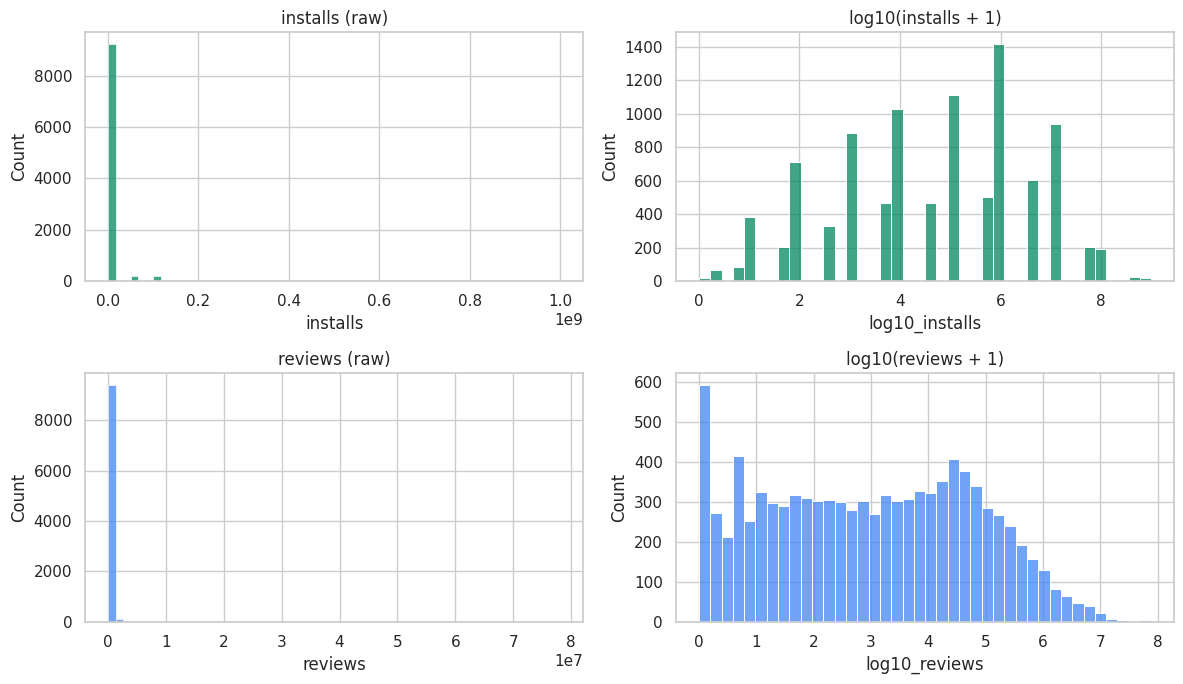

In [27]:
# distributions: heavy right skew
desc = clean_df[["installs", "reviews"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T
desc["skewness"] = clean_df[["installs", "reviews"]].skew()
display(desc)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, color, row in [("installs", GREEN, 0), ("reviews", BLUE, 1)]:
    sns.histplot(clean_df[col], bins=60, ax=axes[row, 0], color=color)
    axes[row, 0].set_title(f"{col} (raw)")
    sns.histplot(clean_df[f"log10_{col}"], bins=40, ax=axes[row, 1], color=color)
    axes[row, 1].set_title(f"log10({col} + 1)")
plt.tight_layout()
plt.savefig(f"{image_path}/01_distributions.png", dpi=150)
plt.show()

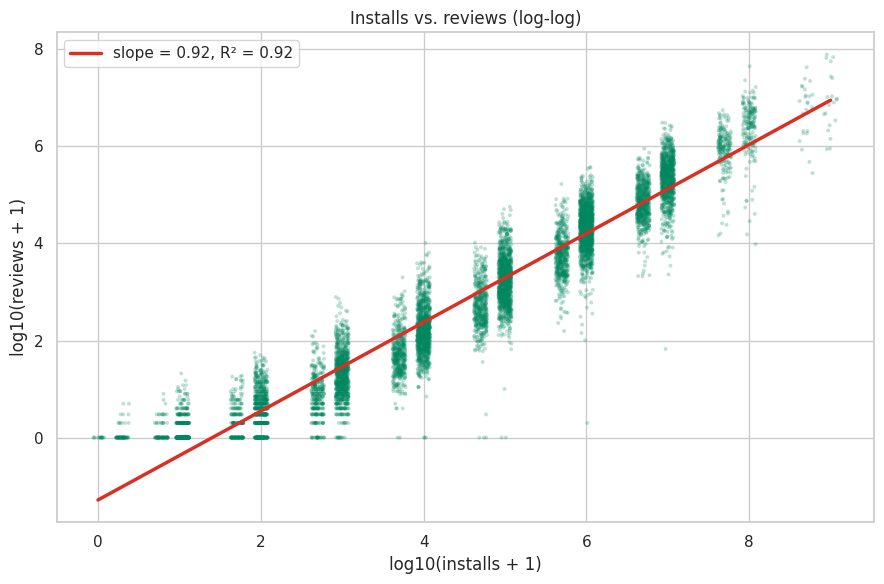

slope 0.916 (95% CI 0.910 to 0.921), R² 0.919, n 9,659
10x installs -> about 8.2x reviews


In [28]:
# log-log relationship with fitted line (jitter is for display only; installs are buckets)
x, y = clean_df["log10_installs"], clean_df["log10_reviews"]
lr = stats.linregress(x, y)
slope_ci = (lr.slope - 1.96 * lr.stderr, lr.slope + 1.96 * lr.stderr)

rng = np.random.default_rng(RANDOM_SEED)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x + rng.uniform(-0.08, 0.08, len(x)), y, s=8, alpha=0.25, color=GREEN, edgecolor="none")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, lr.intercept + lr.slope * xs, color=RED, lw=2.5, label=f"slope = {lr.slope:.2f}, R² = {lr.rvalue**2:.2f}")
ax.set_xlabel("log10(installs + 1)"); ax.set_ylabel("log10(reviews + 1)")
ax.set_title("Installs vs. reviews (log-log)"); ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{image_path}/02_installs_vs_reviews_loglog.png", dpi=150)
plt.show()

print(f"slope {lr.slope:.3f} (95% CI {slope_ci[0]:.3f} to {slope_ci[1]:.3f}), R² {lr.rvalue**2:.3f}, n {len(x):,}")
print(f"10x installs -> about {10 ** lr.slope:.1f}x reviews")

In [29]:
# correlation by four methods, bootstrap ci for spearman, robustness checks
def corr_table(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name, fn, a, b in [
        ("Pearson (raw)",   stats.pearsonr,   df["installs"],       df["reviews"]),
        ("Pearson (log10)", stats.pearsonr,   df["log10_installs"], df["log10_reviews"]),
        ("Spearman (rank)", stats.spearmanr,  df["installs"],       df["reviews"]),
        ("Kendall tau-b",   stats.kendalltau, df["installs"],       df["reviews"]),
    ]:
        res = fn(a, b)
        rows.append((name, float(res[0]), float(res[1]), len(df)))
    out = pd.DataFrame(rows, columns=["method", "coefficient", "p_value", "n"]).set_index("method")
    out["strength"] = out["coefficient"].map(strength_label)
    out["p_value"] = out["p_value"].map(fmt_p)
    return out

def bootstrap_spearman(a: pd.Series, b: pd.Series, n_boot: int = 1000, seed: int = RANDOM_SEED):
    rng = np.random.default_rng(seed)
    a, b, n = a.to_numpy(), b.to_numpy(), len(a)
    vals = np.array([stats.spearmanr(a[i], b[i])[0] for i in (rng.integers(0, n, n) for _ in range(n_boot))])
    return np.percentile(vals, [2.5, 97.5])

corr_df = corr_table(clean_df)
display(corr_df)

ci_lo, ci_hi = bootstrap_spearman(clean_df["installs"], clean_df["reviews"])
rho_s = float(corr_df.loc["Spearman (rank)", "coefficient"])
nz = clean_df[clean_df["reviews"] > 0]
rho_nz = stats.spearmanr(nz["installs"], nz["reviews"])[0]
over = (clean_df["reviews"] > clean_df["installs"]).mean()
print(f"spearman {rho_s:.3f}, bootstrap 95% CI [{ci_lo:.3f}, {ci_hi:.3f}]")
print(f"excluding zero-review apps (n={len(nz):,}): spearman {rho_nz:.3f}")
print(f"apps with more reviews than their install lower bound: {over:.1%}")

,coefficient,p_value,n,strength
method,,,,
Pearson (raw),0.625,< 1e-300,9659,strong
Pearson (log10),0.959,< 1e-300,9659,very strong
Spearman (rank),0.968,< 1e-300,9659,very strong
Kendall tau-b,0.871,< 1e-300,9659,very strong


spearman 0.968, bootstrap 95% CI [0.966, 0.969]
excluding zero-review apps (n=9,066): spearman 0.965
apps with more reviews than their install lower bound: 0.1%


,installs_bucket,apps,installs_min,median_reviews,mean_reviews,median_reviews_per_1k_installs
0,0+,15,0,0.000,0.000,NaN
1,1+,67,1,0.000,0.299,0.000
2,5+,82,5,0.000,0.537,0.000
3,10+,385,10,0.000,1.088,0.000
4,50+,204,50,1.000,2.382,20.000
5,100+,709,100,3.000,5.440,30.000
6,500+,328,500,7.000,12.280,14.000
7,1K+,887,1000,19.000,37.753,19.000
8,5K+,468,5000,48.500,100.098,9.700
9,10K+,1030,10000,158.000,345.266,15.800


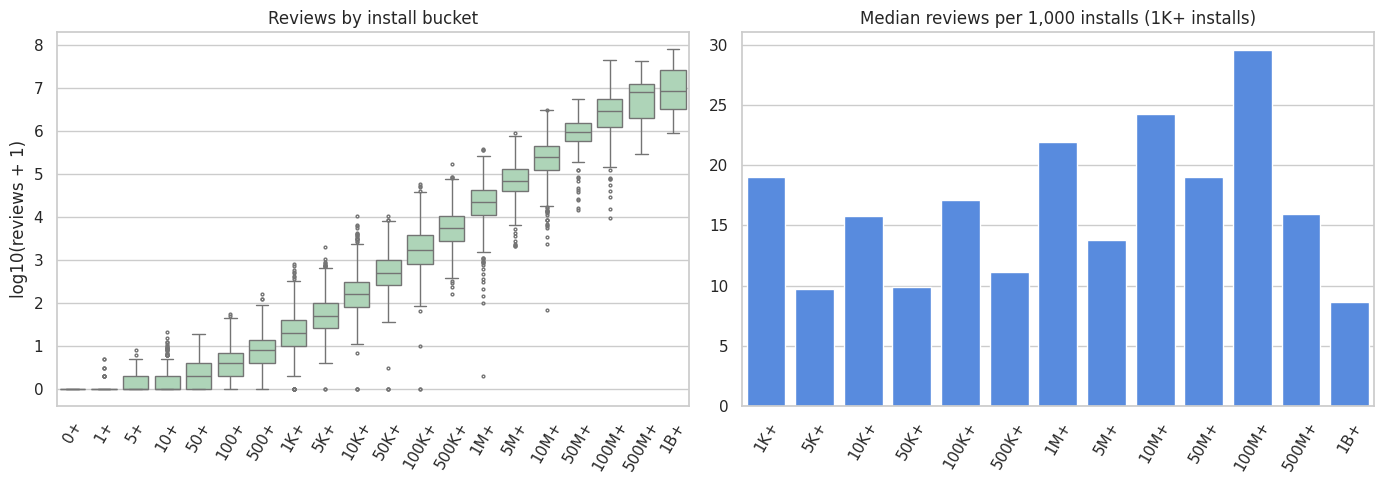

In [30]:
# review rate by install bucket
bucket_stats = (
    clean_df.groupby("installs_bucket", observed=True)
    .agg(apps=("app", "count"), installs_min=("installs", "min"),
         median_reviews=("reviews", "median"), mean_reviews=("reviews", "mean"),
         median_reviews_per_1k_installs=("reviews_per_1k_installs", "median"))
    .reset_index()
)
display(bucket_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=clean_df, x="installs_bucket", y="log10_reviews", ax=axes[0], color="#a8dab5", fliersize=2)
axes[0].set_title("Reviews by install bucket"); axes[0].set_xlabel(""); axes[0].set_ylabel("log10(reviews + 1)")
axes[0].tick_params(axis="x", rotation=60)

rate_stats = bucket_stats[bucket_stats["installs_min"] >= 1_000]   # below 1K the rates are tiny-count noise
sns.barplot(data=rate_stats, x="installs_bucket", y="median_reviews_per_1k_installs", ax=axes[1], color=BLUE,
            order=rate_stats["installs_bucket"].astype(str).tolist())
axes[1].set_title("Median reviews per 1,000 installs (1K+ installs)"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(f"{image_path}/03_buckets.png", dpi=150)
plt.show()

monotonic = bool(bucket_stats["median_reviews"].is_monotonic_increasing)

,apps,spearman_rho
count,33.000,33.000
min,53.000,0.871
50%,219.000,0.961
max,"1,874.000",0.976


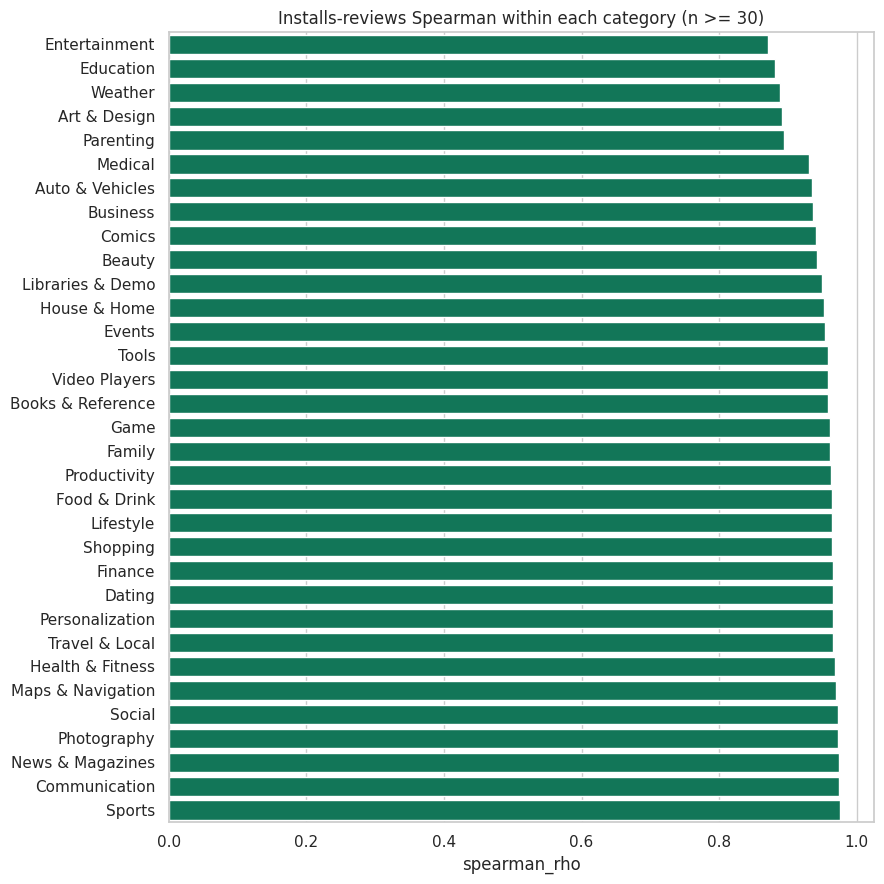

within-category pearson (log scale, category means removed): 0.955


,apps,spearman_rho,median_reviews_per_1k_installs
type,,,
Free,8905,0.971,15.640
Paid,754,0.958,60.500


In [31]:
# within-category check (rules out a category-mix explanation)
def category_spearman(df: pd.DataFrame, min_n: int = MIN_N) -> pd.DataFrame:
    rows = [(cat, len(g), stats.spearmanr(g["installs"], g["reviews"])[0])
            for cat, g in df.groupby("category")
            if len(g) >= min_n and g["installs"].nunique() > 1 and g["reviews"].nunique() > 1]
    return pd.DataFrame(rows, columns=["category", "apps", "spearman_rho"]).sort_values("spearman_rho")

cat_corr = category_spearman(clean_df)
display(cat_corr.describe().loc[["count", "min", "50%", "max"]])

fig, ax = plt.subplots(figsize=(9, 9))
sns.barplot(data=cat_corr, y="category", x="spearman_rho", color=GREEN, ax=ax)
ax.set_title(f"Installs-reviews Spearman within each category (n >= {MIN_N})"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"{image_path}/04_category_correlation.png", dpi=150)
plt.show()

x_w = clean_df["log10_installs"] - clean_df.groupby("category")["log10_installs"].transform("mean")
y_w = clean_df["log10_reviews"] - clean_df.groupby("category")["log10_reviews"].transform("mean")
r_within = float(np.corrcoef(x_w, y_w)[0, 1])
print(f"within-category pearson (log scale, category means removed): {r_within:.3f}")

type_corr = pd.DataFrame([
    {"type": t, "apps": len(g), "spearman_rho": stats.spearmanr(g["installs"], g["reviews"])[0],
     "median_reviews_per_1k_installs": g["reviews_per_1k_installs"].median()}
    for t, g in clean_df.groupby("type")]).set_index("type")
display(type_corr)

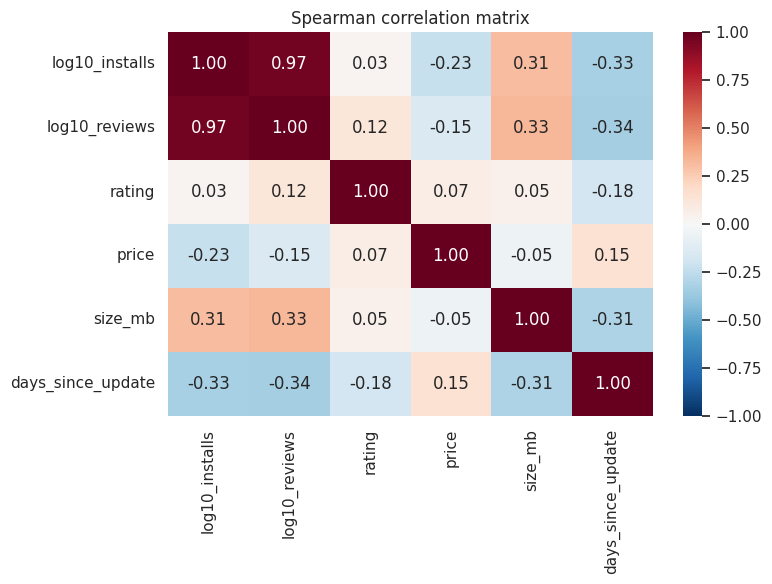

,spearman_with_installs,strength
log10_reviews,0.968,very strong
days_since_update,-0.332,weak
size_mb,0.310,weak
price,-0.232,weak
rating,0.027,negligible


In [32]:
# other attributes vs installs (spearman handles skew)
cols = ["log10_installs", "log10_reviews", "rating", "price", "size_mb", "days_since_update"]
matrix = clean_df[cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.savefig(f"{image_path}/05_correlation_matrix.png", dpi=150)
plt.show()

ranked = (matrix["log10_installs"].drop("log10_installs").to_frame("spearman_with_installs")
          .assign(strength=lambda d: d["spearman_with_installs"].map(strength_label),
                  abs_rho=lambda d: d["spearman_with_installs"].abs())
          .sort_values("abs_rho", ascending=False).drop(columns="abs_rho"))
display(ranked)

In [33]:
# residual outliers: apps far from the log-log line (installs >= 1,000 to avoid tiny-count noise)
df_res = clean_df.copy()
df_res["expected_log_reviews"] = lr.intercept + lr.slope * df_res["log10_installs"]
df_res["residual"] = df_res["log10_reviews"] - df_res["expected_log_reviews"]
df_res["expected_reviews"] = (10 ** df_res["expected_log_reviews"] - 1).round(0)

pool = df_res[df_res["installs"] >= 1_000]
show_cols = ["app", "category", "installs", "reviews", "expected_reviews", "residual"]
print("more reviews than installs predict:")
display(pool.nlargest(10, "residual")[show_cols])
print("fewer reviews than installs predict:")
display(pool.nsmallest(10, "residual")[show_cols])

resid_sd = df_res["residual"].std()
print(f"residual sd (log10): {resid_sd:.3f} -> typical app within {10 ** resid_sd:.1f}x of the prediction")

more reviews than installs predict:


,app,category,installs,reviews,expected_reviews,residual
9129,Alarmy (Sleep If U Can) - Pro,Lifestyle,10000,10249,237.000,1.635
4253,Clash of Clans,Game,100000000,44893888,"1,091,466.000",1.614
1579,ai.type keyboard Plus + Emoji,Tools,100000,57076,"1,955.000",1.465
2383,Be Stronger,Health & Fitness,1000,787,28.000,1.436
9155,My Movies Pro - Movie & TV Collection Library,Lifestyle,10000,6477,237.000,1.436
8126,Day R Premium,Family,100000,51068,"1,955.000",1.417
6053,BZ Reminder PRO,Business,1000,726,28.000,1.401
7779,Carrier Landings Pro,Family,10000,5969,237.000,1.400
8244,Ski Safari: Adventure Time,Family,100000,48754,"1,955.000",1.397
4742,Flud (Ad free),Video Players,10000,5639,237.000,1.376


fewer reviews than installs predict:


,app,category,installs,reviews,expected_reviews,residual
1617,Android TV Remote Service,Tools,1000000,1,"16,100.000",-3.906
1786,Google app for Android TV,Tools,10000000,66,"132,566.000",-3.296
460,Nougat Android 7 Launcher : AW,Personalization,100000,0,"1,955.000",-3.291
8158,Explora con el Chavo,Family,100000,0,"1,955.000",-3.291
3580,Simple x3DS Emulator - BETA,Game,50000,0,"1,036.000",-3.016
7946,AQ: First Contact,Family,50000,0,"1,036.000",-3.016
7947,AR Dragon Pet,Family,50000,0,"1,036.000",-3.016
131,SH-02J Owner's Manual (Android 8.0),Books & Reference,50000,2,"1,036.000",-2.539
2413,"Period Tracker, Pregnancy Calculator & Calendar 🌸",Health & Fitness,10000,0,237.000,-2.376
2795,DW,News & Magazines,10000,0,237.000,-2.376


residual sd (log10): 0.516 -> typical app within 3.3x of the prediction


In [34]:
# answer RQ1 (generated from the results above)
rho_pearson_log = float(corr_df.loc["Pearson (log10)", "coefficient"])
rho_pearson_raw = float(corr_df.loc["Pearson (raw)", "coefficient"])
kendall = float(corr_df.loc["Kendall tau-b", "coefficient"])
cat_share_positive = (cat_corr["spearman_rho"] > 0).mean()
others = ranked.drop(index="log10_reviews", errors="ignore")
top_other_name, top_other = others.index[0], others.iloc[0]
rate_pool = bucket_stats[bucket_stats["installs_min"] >= 1_000]["median_reviews_per_1k_installs"]

direction = "positive" if rho_s > 0 else "negative"
verdict = (f"There is no meaningful relationship (Spearman rho = {rho_s:.2f})." if abs(rho_s) < 0.2
           else f"Yes: a {strength_label(rho_s)} {direction} relationship.")

ANSWERS["RQ1"] = (f"{strength_label(rho_s).capitalize()} {direction} relationship: Spearman rho = {rho_s:.3f} "
                  f"(95% CI {ci_lo:.3f} to {ci_hi:.3f}); each 10x more installs goes with about {10 ** lr.slope:.1f}x more reviews "
                  f"(R² = {lr.rvalue**2:.2f}); positive in {cat_share_positive:.0%} of categories.")

display(Markdown(f"""
**Answer to RQ1.** {verdict}

- Spearman rho = **{rho_s:.3f}** (bootstrap 95% CI {ci_lo:.3f} to {ci_hi:.3f}); Kendall tau-b = {kendall:.3f}.
- Pearson on log values = {rho_pearson_log:.3f}; on raw counts = {rho_pearson_raw:.3f}, which is pulled down by a few blockbuster apps.
- Log-log slope = **{lr.slope:.3f}** (95% CI {slope_ci[0]:.3f} to {slope_ci[1]:.3f}), R² = {lr.rvalue**2:.3f}: each 10x increase in installs goes with about **{10 ** lr.slope:.1f}x** more reviews.
- Median reviews per 1,000 installs (1K+ installs) ranges from {rate_pool.min():.1f} to {rate_pool.max():.1f}. Median reviews {'rise at every step' if monotonic else 'do not rise at every step'} of the install ladder.
- Positive in {cat_share_positive:.0%} of categories with at least {MIN_N} apps (median within-category rho {cat_corr['spearman_rho'].median():.3f}); within-category log correlation {r_within:.3f}.
- Strongest non-review correlate of installs: `{top_other_name}` (rho {top_other['spearman_with_installs']:.2f}, {top_other['strength']}).
- Excluding zero-review apps: rho = {rho_nz:.3f}.
"""))


**Answer to RQ1.** Yes: a very strong positive relationship.

- Spearman rho = **0.968** (bootstrap 95% CI 0.966 to 0.969); Kendall tau-b = 0.871.
- Pearson on log values = 0.959; on raw counts = 0.625, which is pulled down by a few blockbuster apps.
- Log-log slope = **0.916** (95% CI 0.910 to 0.921), R² = 0.919: each 10x increase in installs goes with about **8.2x** more reviews.
- Median reviews per 1,000 installs (1K+ installs) ranges from 8.6 to 29.6. Median reviews rise at every step of the install ladder.
- Positive in 100% of categories with at least 30 apps (median within-category rho 0.961); within-category log correlation 0.955.
- Strongest non-review correlate of installs: `days_since_update` (rho -0.33, weak).
- Excluding zero-review apps: rho = 0.965.


*Caveats.* Association only: more installs create more potential reviewers, and visible reviews can attract installs. Installs are bucket lower bounds, so some apps have more reviews than their bucket floor. Both counts are cumulative, so older apps have had more time to collect both and app age is not in the data.

#### RQ2. Which categories have the best ratings?

,group,apps,median_installs,median_reviews
0,rated,8196,"100,000.000","3,017.000"
1,unrated,1463,100.000,1.000


unrated share: 15.1% | cliff's delta (unrated vs rated installs): -0.88 (large)


,category,rated_apps,median_rating,mean_rating,ci_low,ci_high,pct_4_5_plus,median_installs,total_installs
0,Events,45,4.500,4.436,4.400,4.600,53.333,"50,000.000",15949410
1,Books & Reference,169,4.500,4.345,4.400,4.500,51.479,"100,000.000",1665791655
2,Health & Fitness,244,4.500,4.243,4.400,4.500,51.230,"500,000.000",1144006220
3,Art & Design,59,4.400,4.359,4.200,4.500,42.373,"100,000.000",113233100
4,Education,106,4.400,4.355,4.300,4.400,39.623,"1,000,000.000",189852000
5,Personalization,298,4.400,4.332,4.300,4.400,39.933,"100,000.000",1532352930
6,Parenting,50,4.400,4.300,4.200,4.600,46.000,"100,000.000",31116110
7,Comics,54,4.400,4.181,4.100,4.450,37.037,"100,000.000",44931100
8,Beauty,42,4.300,4.279,4.100,4.500,38.095,"100,000.000",26916200
9,Social,203,4.300,4.247,4.200,4.300,31.527,"500,000.000",5487841475


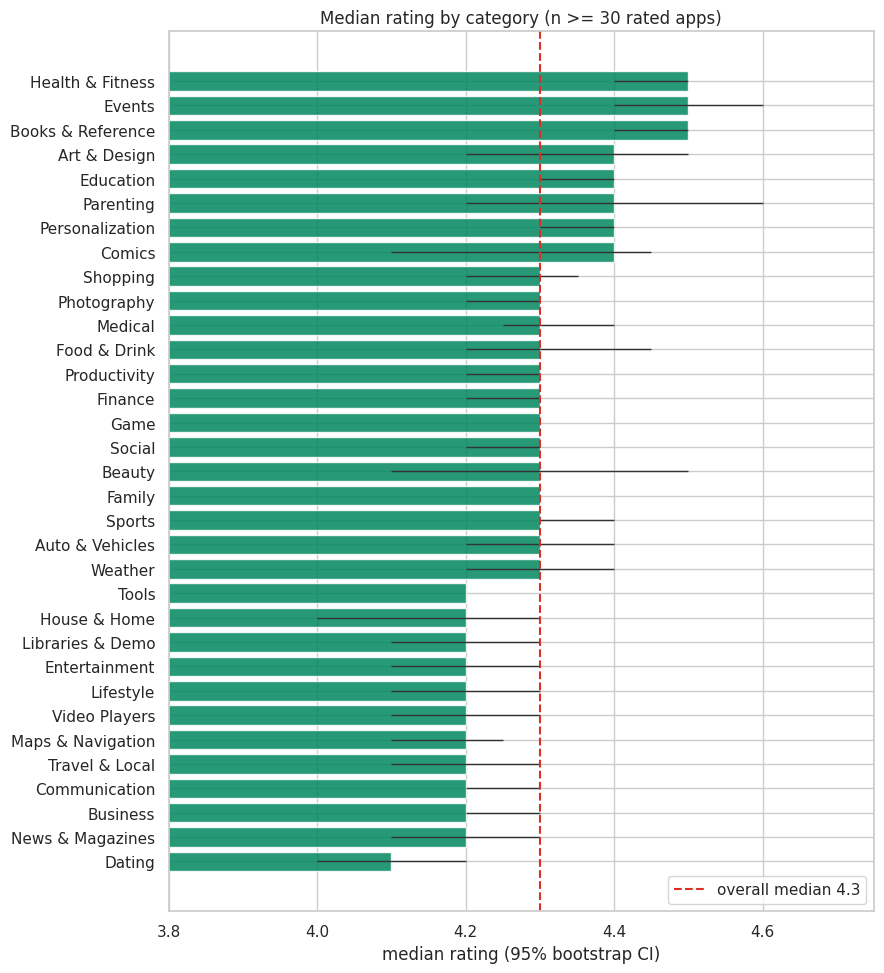


**Answer to RQ2.**

- Best-rated: Events (4.5, n=45), Books & Reference (4.5, n=169), Health & Fitness (4.5, n=244).
- Lowest-rated: Tools (4.2, n=720), Maps & Navigation (4.2, n=118), Dating (4.1, n=133).
- Kruskal-Wallis H = 238.8, p = 1.71e-33; epsilon² = **0.025** (small). The top and bottom category CIs do not overlap.
- Top quartile on both rating and median installs: Education, Game, Weather, Shopping, Food & Drink, Photography.
- The top groups are small (smallest n = 45), so read the top ranks as a tier, not an exact order. Medians of 1-5 ratings have many ties, so means and the 4.5+ share are in the table. Ratings exist only for apps that attracted reviews: unrated apps are far less installed (see selection check).


In [35]:
rated = clean_df.dropna(subset=["rating"]).copy()
unrated = clean_df[clean_df["rating"].isna()]

# selection check: are unrated apps less popular?
delta_miss = cliffs_delta(unrated["installs"], rated["installs"])
display(pd.DataFrame({
    "group": ["rated", "unrated"], "apps": [len(rated), len(unrated)],
    "median_installs": [rated["installs"].median(), unrated["installs"].median()],
    "median_reviews": [rated["reviews"].median(), unrated["reviews"].median()]}))
print(f"unrated share: {len(unrated) / len(clean_df):.1%} | cliff's delta (unrated vs rated installs): {delta_miss:.2f} ({delta_label(delta_miss)})")

def category_rating_table(df: pd.DataFrame, min_n: int = MIN_N) -> pd.DataFrame:
    rows = []
    for cat, g in df.groupby("category"):
        if len(g) >= min_n:
            lo, hi = bootstrap_median_ci(g["rating"])
            rows.append(dict(category=cat, rated_apps=len(g), median_rating=g["rating"].median(),
                             mean_rating=g["rating"].mean(), ci_low=lo, ci_high=hi,
                             pct_4_5_plus=(g["rating"] >= 4.5).mean() * 100,
                             median_installs=g["installs"].median(), total_installs=g["installs"].sum()))
    return pd.DataFrame(rows).sort_values(["median_rating", "mean_rating"], ascending=False).reset_index(drop=True)

ct = category_rating_table(rated)
display(ct.head(10))

H, p_kw, eps2 = epsilon_squared([g["rating"].to_numpy() for _, g in rated.groupby("category") if len(g) >= MIN_N])

order = ct.sort_values("median_rating")
err = [(order["median_rating"] - order["ci_low"]).clip(lower=0), (order["ci_high"] - order["median_rating"]).clip(lower=0)]
fig, ax = plt.subplots(figsize=(9, max(5, 0.3 * len(order))))
ax.barh(order["category"], order["median_rating"], xerr=err, color=GREEN, alpha=0.85, error_kw=dict(ecolor="#333", lw=1))
ax.axvline(rated["rating"].median(), color=RED, ls="--", label=f"overall median {rated['rating'].median():.1f}")
ax.set_xlim(max(1, order["ci_low"].min() - 0.2), min(5, order["ci_high"].max() + 0.15))
ax.set_xlabel("median rating (95% bootstrap CI)"); ax.set_ylabel("")
ax.set_title(f"Median rating by category (n >= {MIN_N} rated apps)"); ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{image_path}/06_category_ratings.png", dpi=150)
plt.show()

q_rating, q_inst = ct["median_rating"].quantile(0.75), ct["median_installs"].quantile(0.75)
both = ct[(ct["median_rating"] >= q_rating) & (ct["median_installs"] >= q_inst)]["category"].tolist()
top3, bot3 = ct.head(3), ct.tail(3)
separable = ct.iloc[0]["ci_low"] > ct.iloc[-1]["ci_high"]
small_top = int(top3["rated_apps"].min()) < 60

ANSWERS["RQ2"] = (f"Highest median ratings: {', '.join(top3['category'])} ({top3['median_rating'].iloc[0]:.1f}); lowest: "
                  f"{', '.join(bot3['category'])} ({bot3['median_rating'].iloc[-1]:.1f}). Category explains "
                  f"{eps2:.1%} of rating rank variance ({eps2_label(eps2)} effect).")

display(Markdown(f"""
**Answer to RQ2.**

- Best-rated: {', '.join(f"{r.category} ({r.median_rating:.1f}, n={r.rated_apps})" for r in top3.itertuples())}.
- Lowest-rated: {', '.join(f"{r.category} ({r.median_rating:.1f}, n={r.rated_apps})" for r in bot3.itertuples())}.
- Kruskal-Wallis H = {H:.1f}, p = {fmt_p(p_kw)}; epsilon² = **{eps2:.3f}** ({eps2_label(eps2)}). The top and bottom category CIs {'do not overlap' if separable else 'overlap'}.
- Top quartile on both rating and median installs: {', '.join(both) if both else 'none'}.
- {'The top groups are small (smallest n = ' + str(int(top3['rated_apps'].min())) + '), so read the top ranks as a tier, not an exact order. ' if small_top else ''}Medians of 1-5 ratings have many ties, so means and the 4.5+ share are in the table. Ratings exist only for apps that attracted reviews: unrated apps are far less installed (see selection check).
"""))

#### RQ3. Do paid apps earn higher ratings than free apps?

,apps,mean,median,std
type,,,,
Free,7594,4.166,4.300,0.534
Paid,602,4.262,4.400,0.557


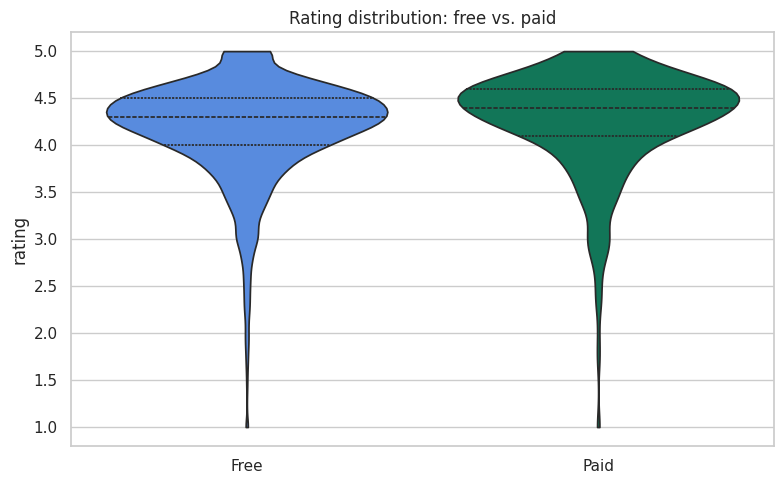


**Answer to RQ3.**

- Mean rating: paid **4.26** (n=602) vs. free **4.17** (n=7,594); difference +0.10 (95% bootstrap CI +0.05 to +0.14); median difference +0.10.
- Mann-Whitney p = 8.11e-11; **Cliff's delta = 0.16 (small)**: a random paid app out-rates a random free app about 58% of the time (50% = no difference).
- Category-adjusted delta = 0.14 (negligible).
- Within the 10 categories with at least 15 apps of each type, paid has the higher mean rating in 80%.
- This is an association, not a price effect: paying users and niche, specialised apps differ from free-app audiences.


In [36]:
def bootstrap_mean_diff_ci(a, b, n_boot: int = 2000, seed: int = RANDOM_SEED):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a, float), np.asarray(b, float)
    ma = rng.choice(a, size=(n_boot, len(a)), replace=True).mean(axis=1)
    mb = rng.choice(b, size=(n_boot, len(b)), replace=True).mean(axis=1)
    return np.percentile(ma - mb, [2.5, 97.5])

free_r = rated.loc[~rated["is_paid"], "rating"]
paid_r = rated.loc[rated["is_paid"], "rating"]

mw = stats.mannwhitneyu(paid_r, free_r, alternative="two-sided")
d3 = cliffs_delta(paid_r, free_r)
mean_diff = paid_r.mean() - free_r.mean()
med_diff = paid_r.median() - free_r.median()
mdiff_lo, mdiff_hi = bootstrap_mean_diff_ci(paid_r, free_r)

# category-adjusted: subtract each category's mean rating, then compare again
rated["rating_adj"] = rated["rating"] - rated.groupby("category")["rating"].transform("mean")
d3_adj = cliffs_delta(rated.loc[rated["is_paid"], "rating_adj"], rated.loc[~rated["is_paid"], "rating_adj"])

rows = []
for cat, g in rated.groupby("category"):
    a, b = g.loc[g["is_paid"], "rating"], g.loc[~g["is_paid"], "rating"]
    if len(a) >= 15 and len(b) >= 15:
        rows.append((cat, len(a), len(b), a.median() - b.median(), a.mean() - b.mean()))
within3 = pd.DataFrame(rows, columns=["category", "paid_n", "free_n", "median_diff", "mean_diff"])
share_paid_higher = (within3["mean_diff"] > 0).mean() if len(within3) else float("nan")

display(rated.groupby("type")["rating"].agg(apps="count", mean="mean", median="median", std="std"))

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=rated, x="type", y="rating", order=["Free", "Paid"], hue="type", palette=[BLUE, GREEN],
               inner="quartile", cut=0, legend=False, ax=ax)
ax.set_title("Rating distribution: free vs. paid"); ax.set_xlabel(""); ax.set_ylabel("rating")
plt.tight_layout()
plt.savefig(f"{image_path}/07_rating_free_vs_paid.png", dpi=150)
plt.show()

ANSWERS["RQ3"] = (f"Paid apps average {mean_diff:+.2f} rating points vs. free (95% CI {mdiff_lo:+.2f} to {mdiff_hi:+.2f}); "
                  f"Cliff's delta {d3:.2f} ({delta_label(d3)}); after category adjustment {d3_adj:.2f} ({delta_label(d3_adj)}).")

display(Markdown(f"""
**Answer to RQ3.**

- Mean rating: paid **{paid_r.mean():.2f}** (n={len(paid_r):,}) vs. free **{free_r.mean():.2f}** (n={len(free_r):,}); difference {mean_diff:+.2f} (95% bootstrap CI {mdiff_lo:+.2f} to {mdiff_hi:+.2f}); median difference {med_diff:+.2f}.
- Mann-Whitney p = {fmt_p(mw.pvalue)}; **Cliff's delta = {d3:.2f} ({delta_label(d3)})**: a random paid app out-rates a random free app about {(d3 + 1) / 2:.0%} of the time (50% = no difference).
- Category-adjusted delta = {d3_adj:.2f} ({delta_label(d3_adj)}).
- Within the {len(within3)} categories with at least 15 apps of each type, paid has the higher mean rating in {share_paid_higher:.0%}.
- This is an association, not a price effect: paying users and niche, specialised apps differ from free-app audiences.
"""))

#### RQ4. How does app size relate to installs and ratings?

,size_band,apps,median_installs,median_rating,pct_1m_plus
0,<5 MB,2263,"5,000.000",4.200,13.522
1,5-15 MB,2384,"10,000.000",4.300,25.336
2,15-30 MB,1800,"50,000.000",4.300,33.333
3,30-60 MB,1353,"500,000.000",4.300,45.455
4,60+ MB,631,"1,000,000.000",4.300,58.003
5,Varies with device,1228,"5,000,000.000",4.300,73.860


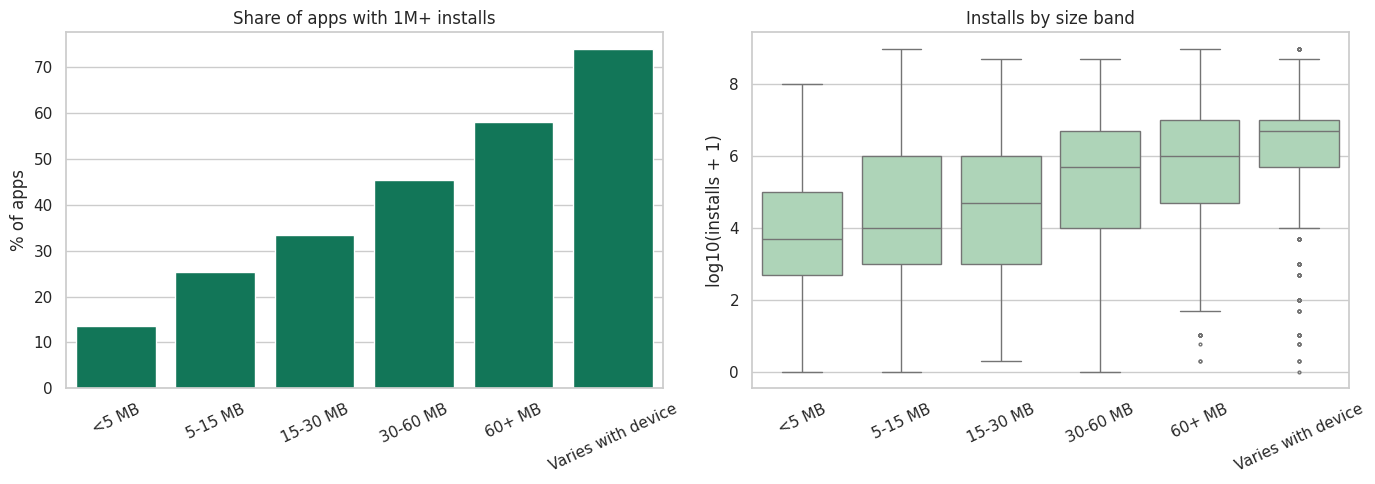


**Answer to RQ4.**

- Size vs. installs: rho = **0.31** (weak, positive; p = 2.13e-187, n = 8,431); category-adjusted log correlation 0.24.
- Size vs. rating: rho = 0.05 (negligible). Size vs. reviews: rho = 0.33.
- Share of apps with 1M+ installs: 58.0% in the 60+ MB band vs. 13.5% in the <5 MB band.
- "Varies with device" apps (n=1,228): median installs 5,000,000 vs. 50,000 for fixed-size apps (Cliff's delta 0.56, large).
- The hypothesis that larger apps have fewer installs is not supported (larger apps tend to be installed more). Size likely proxies app complexity and category.


In [37]:
sized = clean_df.dropna(subset=["size_mb"]).copy()
sized_r = sized.dropna(subset=["rating"])
rho_si = stats.spearmanr(sized["size_mb"], sized["installs"])
rho_sr = stats.spearmanr(sized_r["size_mb"], sized_r["rating"])
rho_sv = stats.spearmanr(sized["size_mb"], sized["reviews"])

xs_ = sized["log10_size_mb"] - sized.groupby("category")["log10_size_mb"].transform("mean")
ys_ = sized["log10_installs"] - sized.groupby("category")["log10_installs"].transform("mean")
r_size_within = float(np.corrcoef(xs_, ys_)[0, 1])

size_stats = (clean_df.groupby("size_band", observed=True)
              .agg(apps=("app", "count"), median_installs=("installs", "median"), median_rating=("rating", "median"),
                   pct_1m_plus=("installs", lambda s: (s >= 1_000_000).mean() * 100))
              .reset_index())
display(size_stats)

varies = clean_df[clean_df["size_missing"]]
d4 = cliffs_delta(varies["installs"], sized["installs"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=size_stats, x="size_band", y="pct_1m_plus", color=GREEN, ax=axes[0])
axes[0].set_title("Share of apps with 1M+ installs"); axes[0].set_xlabel(""); axes[0].set_ylabel("% of apps")
axes[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=clean_df, x="size_band", y="log10_installs", color="#a8dab5", fliersize=2, ax=axes[1])
axes[1].set_title("Installs by size band"); axes[1].set_xlabel(""); axes[1].set_ylabel("log10(installs + 1)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(f"{image_path}/08_size_vs_installs.png", dpi=150)
plt.show()

known = size_stats[size_stats["size_band"] != "Varies with device"]
peak_band = known.loc[known["pct_1m_plus"].idxmax(), "size_band"]
low_band = known.loc[known["pct_1m_plus"].idxmin(), "size_band"]
shape = "positive" if rho_si[0] > 0 else "negative"

ANSWERS["RQ4"] = (f"Size vs. installs: Spearman rho = {rho_si[0]:.2f} ({strength_label(rho_si[0])} {shape}); "
                  f"1M+ install share peaks in the {peak_band} band; size vs. rating rho = {rho_sr[0]:.2f}.")

display(Markdown(f"""
**Answer to RQ4.**

- Size vs. installs: rho = **{rho_si[0]:.2f}** ({strength_label(rho_si[0])}, {shape}; p = {fmt_p(rho_si[1])}, n = {len(sized):,}); category-adjusted log correlation {r_size_within:.2f}.
- Size vs. rating: rho = {rho_sr[0]:.2f} ({strength_label(rho_sr[0])}). Size vs. reviews: rho = {rho_sv[0]:.2f}.
- Share of apps with 1M+ installs: {known['pct_1m_plus'].max():.1f}% in the {peak_band} band vs. {known['pct_1m_plus'].min():.1f}% in the {low_band} band.
- "Varies with device" apps (n={len(varies):,}): median installs {varies['installs'].median():,.0f} vs. {sized['installs'].median():,.0f} for fixed-size apps (Cliff's delta {d4:.2f}, {delta_label(d4)}).
- The hypothesis that larger apps have fewer installs is {'supported' if rho_si[0] <= -0.2 else 'not supported'} ({'larger apps tend to be installed less' if rho_si[0] <= -0.2 else 'larger apps tend to be installed more' if rho_si[0] >= 0.2 else 'little rank relationship'}). Size likely proxies app complexity and category.
"""))

#### RQ5. How does price relate to installs?

,price_band,apps,median_installs,pct_100k_plus,median_rating
0,Free,8905,"100,000.000",55.025,4.300
1,$0.01-0.99,145,500.000,10.345,4.400
2,$1-2.99,293,"1,000.000",16.041,4.400
3,$3-9.99,241,"5,000.000",19.917,4.400
4,$10+,75,"1,000.000",6.667,4.200


apps priced at $100 or more: 20


,app,category,price,installs
9151,I'm Rich - Trump Edition,Lifestyle,400.000,10000
2048,I AM RICH PRO PLUS,Finance,399.990,1000
2049,I am Rich!,Finance,399.990,1000
2050,I am rich (Most expensive app),Finance,399.990,1000
2075,I am Rich,Finance,399.990,5000


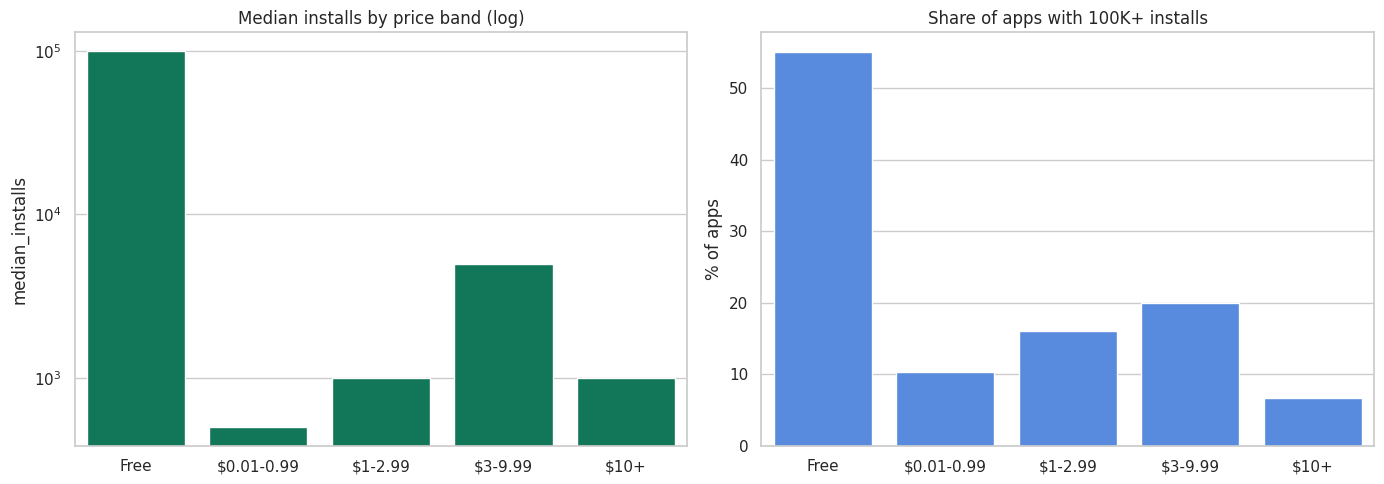


**Answer to RQ5.**

- Median installs: free **100,000** vs. paid **1,000** (8,905 vs. 754 apps). Mann-Whitney p = 7.96e-116; **Cliff's delta = 0.50 (large)**: a random free app out-installs a random paid app about 75% of the time.
- Among paid apps: price vs. installs rho = **0.13** (negligible, n = 754); price vs. rating rho = -0.10 (n = 602, unrated apps excluded).
- Share with 100K+ installs: 6.7% to 19.9% across paid bands vs. 55.0% for free.
- Charging goes with clearly lower reach; among paid apps, price level has little rank relationship with installs.
- 20 apps cost $100 or more (novelty listings); rank-based results are barely affected.


In [38]:
paid = clean_df[clean_df["is_paid"]]
free = clean_df[~clean_df["is_paid"]]

mw5 = stats.mannwhitneyu(free["installs"], paid["installs"], alternative="two-sided")
d5 = cliffs_delta(free["installs"], paid["installs"])
rho_pp = stats.spearmanr(paid["price"], paid["installs"])
paid_rated = paid.dropna(subset=["rating"])
rho_pr = stats.spearmanr(paid_rated["price"], paid_rated["rating"])

price_stats = (clean_df.groupby("price_band", observed=True)
               .agg(apps=("app", "count"), median_installs=("installs", "median"),
                    pct_100k_plus=("installs", lambda s: (s >= 100_000).mean() * 100),
                    median_rating=("rating", "median"))
               .reset_index())
display(price_stats)

expensive = clean_df[clean_df["price"] >= 100]
print(f"apps priced at $100 or more: {len(expensive)}")
display(expensive.nlargest(5, "price")[["app", "category", "price", "installs"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=price_stats, x="price_band", y="median_installs", color=GREEN, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Median installs by price band (log)"); axes[0].set_xlabel("")
sns.barplot(data=price_stats, x="price_band", y="pct_100k_plus", color=BLUE, ax=axes[1])
axes[1].set_title("Share of apps with 100K+ installs"); axes[1].set_xlabel(""); axes[1].set_ylabel("% of apps")
plt.tight_layout()
plt.savefig(f"{image_path}/09_price_vs_installs.png", dpi=150)
plt.show()

paid_bands = price_stats[price_stats["price_band"] != "Free"]
free_share = price_stats.loc[price_stats["price_band"] == "Free", "pct_100k_plus"].iloc[0]
reach_gap = "clearly lower" if d5 >= 0.33 else "modestly lower" if d5 >= 0.147 else "no meaningfully different"

ANSWERS["RQ5"] = (f"Free apps have a median of {free['installs'].median():,.0f} installs vs. {paid['installs'].median():,.0f} for paid "
                  f"(Cliff's delta {d5:.2f}, {delta_label(d5)}); among paid apps price vs. installs rho = {rho_pp[0]:.2f}.")

display(Markdown(f"""
**Answer to RQ5.**

- Median installs: free **{free['installs'].median():,.0f}** vs. paid **{paid['installs'].median():,.0f}** ({len(free):,} vs. {len(paid):,} apps). Mann-Whitney p = {fmt_p(mw5.pvalue)}; **Cliff's delta = {d5:.2f} ({delta_label(d5)})**: a random free app out-installs a random paid app about {(d5 + 1) / 2:.0%} of the time.
- Among paid apps: price vs. installs rho = **{rho_pp[0]:.2f}** ({strength_label(rho_pp[0])}, n = {len(paid):,}); price vs. rating rho = {rho_pr[0]:.2f} (n = {len(paid_rated):,}, unrated apps excluded).
- Share with 100K+ installs: {paid_bands['pct_100k_plus'].min():.1f}% to {paid_bands['pct_100k_plus'].max():.1f}% across paid bands vs. {free_share:.1f}% for free.
- Charging goes with {reach_gap} reach; among paid apps, {'higher prices go with fewer installs' if rho_pp[0] <= -0.2 else 'price level has little rank relationship with installs'}.
- {len(expensive)} apps cost $100 or more (novelty listings); rank-based results are barely affected.
"""))

#### RQ6. How do installs and ratings vary with update recency?

,recency_band,apps,median_installs,median_rating,mean_rating,pct_1m_plus
0,0-30 days,2936,"1,000,000.000",4.400,4.270,56.744
1,31-90 days,1829,"100,000.000",4.300,4.208,38.928
2,91-365 days,2478,"10,000.000",4.200,4.131,23.164
3,1-2 years,1205,"10,000.000",4.200,4.064,18.174
4,2+ years,1211,"10,000.000",4.200,4.052,18.745


,install_tier,pct_updated_within_180d
0,<10K,49.221
1,10K-1M,55.359
2,1M+,77.987


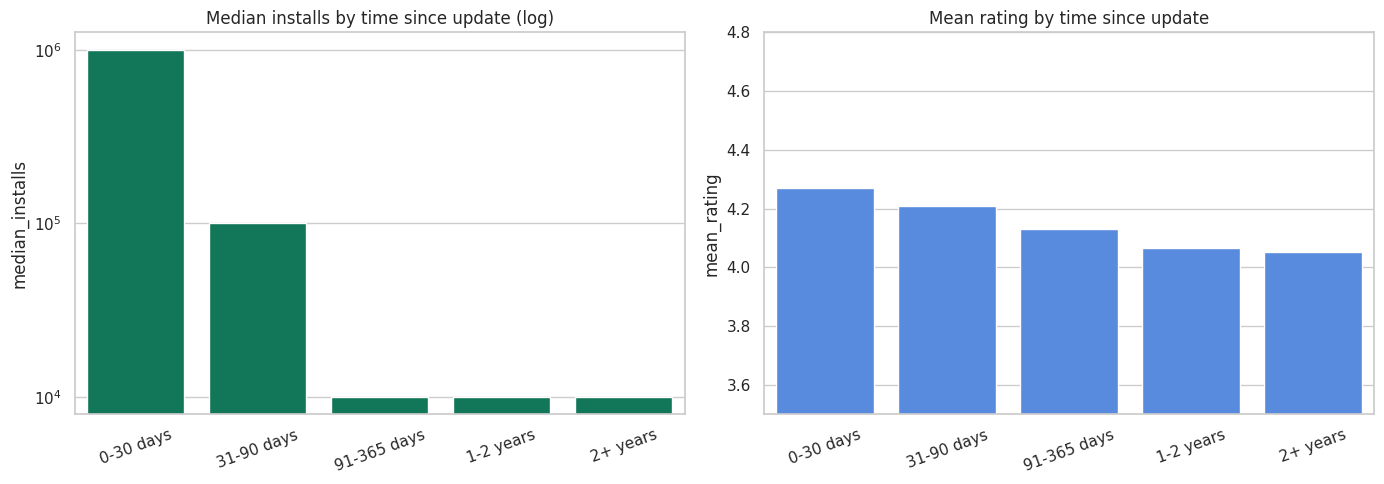


**Answer to RQ6.**

- Days since update vs. installs: rho = **-0.33** (weak; negative means fresher apps have more installs). Vs. reviews: -0.34.
- Vs. rating: rho = **-0.18** (negligible).
- Updated within 180 days of the snapshot: 78% of 1M+ apps, 55% of 10K-1M apps, 49% of <10K apps.
- Frequent updates go with greater reach; the direction of cause is unclear because successful apps can afford to update more often.


In [39]:
rec = clean_df.dropna(subset=["days_since_update"])
rr = rec.dropna(subset=["rating"])
rho_ri = stats.spearmanr(rec["days_since_update"], rec["installs"])
rho_rr = stats.spearmanr(rr["days_since_update"], rr["rating"])
rho_rv = stats.spearmanr(rec["days_since_update"], rec["reviews"])

rec_stats = (clean_df.groupby("recency_band", observed=True)
             .agg(apps=("app", "count"), median_installs=("installs", "median"),
                  median_rating=("rating", "median"), mean_rating=("rating", "mean"),
                  pct_1m_plus=("installs", lambda s: (s >= 1_000_000).mean() * 100))
             .reset_index())
display(rec_stats)

fresh = (clean_df.assign(fresh_180d=clean_df["days_since_update"] <= 180)
         .groupby("install_tier", observed=True)["fresh_180d"].mean().mul(100)
         .rename("pct_updated_within_180d").reset_index())
display(fresh)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=rec_stats, x="recency_band", y="median_installs", color=GREEN, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Median installs by time since update (log)"); axes[0].set_xlabel("")
sns.barplot(data=rec_stats, x="recency_band", y="mean_rating", color=BLUE, ax=axes[1])
axes[1].set_ylim(3.5, 4.8); axes[1].set_title("Mean rating by time since update"); axes[1].set_xlabel("")
for ax in axes: ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(f"{image_path}/10_recency.png", dpi=150)
plt.show()

fr = fresh.set_index("install_tier")["pct_updated_within_180d"]
ANSWERS["RQ6"] = (f"Days since update vs. installs rho = {rho_ri[0]:.2f} ({strength_label(rho_ri[0])}); vs. rating rho = {rho_rr[0]:.2f}; "
                  f"{fr['1M+']:.0f}% of 1M+ apps were updated in the last 180 days vs. {fr['<10K']:.0f}% of <10K apps.")

display(Markdown(f"""
**Answer to RQ6.**

- Days since update vs. installs: rho = **{rho_ri[0]:.2f}** ({strength_label(rho_ri[0])}; negative means fresher apps have more installs). Vs. reviews: {rho_rv[0]:.2f}.
- Vs. rating: rho = **{rho_rr[0]:.2f}** ({strength_label(rho_rr[0])}).
- Updated within 180 days of the snapshot: {fr['1M+']:.0f}% of 1M+ apps, {fr['10K-1M']:.0f}% of 10K-1M apps, {fr['<10K']:.0f}% of <10K apps.
- {'Frequent updates go with greater reach' if rho_ri[0] <= -0.2 else 'Update recency is only weakly linked to reach'}; the direction of cause is unclear because successful apps can afford to update more often.
"""))

#### RQ7. Which content-rating groups and genres dominate, and which genres are crowded?

,content_rating,apps,total_installs,median_installs,median_rating,pct_apps,pct_installs
0,Everyone,7903,52378941861,"50,000.000",4.300,81.820,69.540
1,Teen,1036,16487275393,"500,000.000",4.300,10.726,21.889
2,Mature 17+,393,2437986878,"500,000.000",4.200,4.069,3.237
3,Everyone 10+,322,4016271795,"1,000,000.000",4.300,3.334,5.332
4,Adults only 18+,3,2000000,"500,000.000",4.500,0.031,0.003
5,Unrated,2,50500,"25,250.000",4.100,0.021,0.000


,primary_genre,apps,total_installs,median_installs,median_rating,pct_apps,pct_installs,saturation_index
0,Tools,829,8102771915,"50,000.000",4.200,8.583,10.757,0.798
1,Entertainment,592,3160114684,"50,000.000",4.200,6.129,4.195,1.461
2,Education,580,452160708,"10,000.000",4.400,6.005,0.600,10.003
3,Business,420,697164865,"1,000.000",4.200,4.348,0.926,4.698
4,Medical,395,38293077,"1,000.000",4.300,4.089,0.051,80.440
5,Personalization,376,1532494782,"10,000.000",4.400,3.893,2.035,1.913
6,Productivity,374,5793091369,"100,000.000",4.300,3.872,7.691,0.503
7,Lifestyle,370,503923539,"10,000.000",4.200,3.831,0.669,5.726
8,Finance,345,455348734,"10,000.000",4.300,3.572,0.605,5.908
9,Sports,335,1423174498,"100,000.000",4.300,3.468,1.889,1.836


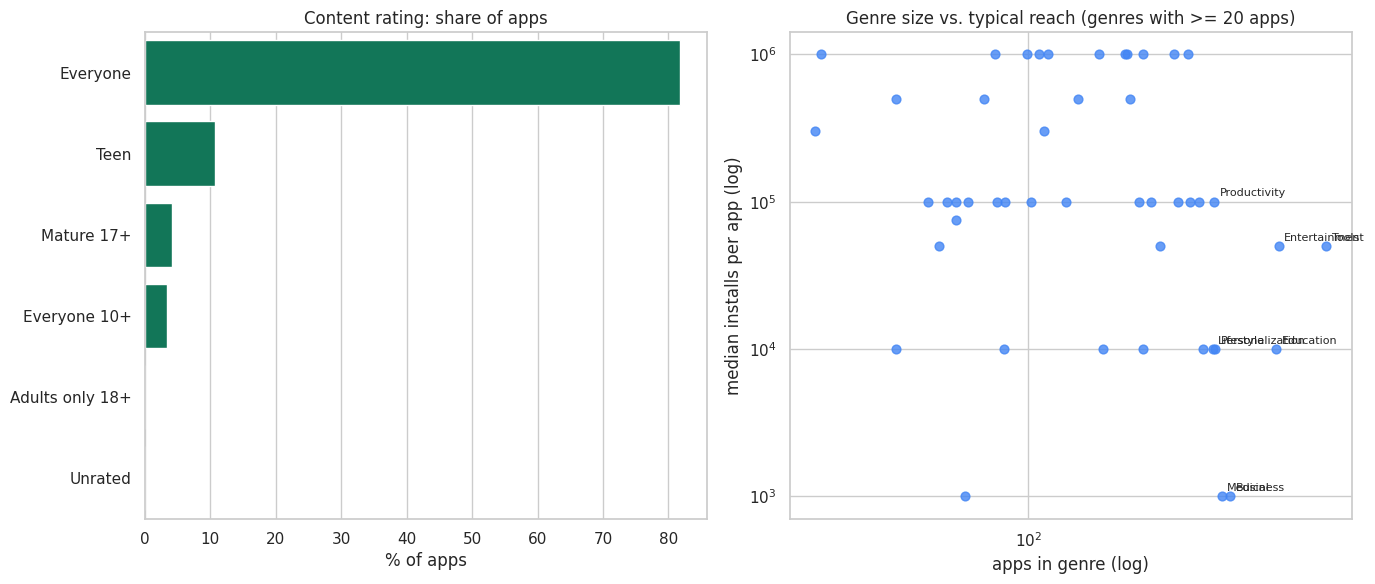


**Answer to RQ7.**

- `Everyone` apps are **82%** of listings and **70%** of installs; next is `Teen` (11% of apps).
- The five largest primary genres hold **29%** of apps. HHI = 0.036 across 48 genres (even spread = 0.021): fairly spread out.
- Genre size vs. median installs per app (genres with >= 20 apps): rho = -0.28 (crowded genres tend to offer lower reach per app). Large genres with the lowest typical reach: Business (420 apps, median 1,000), Medical (395 apps, median 1,000), Education (580 apps, median 10,000).
- Highest saturation index (>= 20 apps): Medical (80.4), Events (31.2), Beauty (15.2). Lowest: Communication (0.2), Video Players & Editors (0.3), Social (0.3).


In [40]:
cr = (clean_df.groupby("content_rating")
      .agg(apps=("app", "count"), total_installs=("installs", "sum"),
           median_installs=("installs", "median"), median_rating=("rating", "median"))
      .assign(pct_apps=lambda d: d["apps"] / d["apps"].sum() * 100,
              pct_installs=lambda d: d["total_installs"] / d["total_installs"].sum() * 100)
      .sort_values("apps", ascending=False).reset_index())
display(cr)

genre = (clean_df.groupby("primary_genre")
         .agg(apps=("app", "count"), total_installs=("installs", "sum"),
              median_installs=("installs", "median"), median_rating=("rating", "median"))
         .assign(pct_apps=lambda d: d["apps"] / d["apps"].sum() * 100,
                 pct_installs=lambda d: d["total_installs"] / d["total_installs"].sum() * 100)
         .assign(saturation_index=lambda d: d["pct_apps"] / d["pct_installs"])
         .sort_values("apps", ascending=False).reset_index())
genre_big = genre[genre["apps"] >= 20]
display(genre.head(12))

hhi_genre, hhi_even = hhi(genre["apps"]), 1 / len(genre)
top5_share = genre["pct_apps"].head(5).sum()
rho_gc = stats.spearmanr(genre_big["apps"], genre_big["median_installs"])
crowded = genre_big[genre_big["pct_apps"] >= genre_big["pct_apps"].median()].nsmallest(3, "median_installs")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=cr, y="content_rating", x="pct_apps", color=GREEN, ax=axes[0])
axes[0].set_title("Content rating: share of apps"); axes[0].set_xlabel("% of apps"); axes[0].set_ylabel("")
axes[1].scatter(genre_big["apps"], genre_big["median_installs"], s=40, color=BLUE, alpha=0.8)
for r in genre_big.nlargest(8, "apps").itertuples():
    axes[1].annotate(r.primary_genre, (r.apps, r.median_installs), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Genre size vs. typical reach (genres with >= 20 apps)")
axes[1].set_xlabel("apps in genre (log)"); axes[1].set_ylabel("median installs per app (log)")
plt.tight_layout()
plt.savefig(f"{image_path}/11_audience_and_genres.png", dpi=150)
plt.show()

ANSWERS["RQ7"] = (f"'{cr.iloc[0]['content_rating']}' holds {cr.iloc[0]['pct_apps']:.0f}% of apps; top 5 genres hold {top5_share:.0f}% of apps "
                  f"(HHI {hhi_genre:.3f} vs. {hhi_even:.3f} if even); genre size vs. median installs rho = {rho_gc[0]:.2f}.")

display(Markdown(f"""
**Answer to RQ7.**

- `{cr.iloc[0]['content_rating']}` apps are **{cr.iloc[0]['pct_apps']:.0f}%** of listings and **{cr.iloc[0]['pct_installs']:.0f}%** of installs; next is `{cr.iloc[1]['content_rating']}` ({cr.iloc[1]['pct_apps']:.0f}% of apps).
- The five largest primary genres hold **{top5_share:.0f}%** of apps. HHI = {hhi_genre:.3f} across {len(genre)} genres (even spread = {hhi_even:.3f}): {'moderately concentrated' if hhi_genre > 2 * hhi_even else 'fairly spread out'}.
- Genre size vs. median installs per app (genres with >= 20 apps): rho = {rho_gc[0]:.2f} ({'crowded genres tend to offer lower reach per app' if rho_gc[0] <= -0.2 else 'crowded genres tend to offer higher reach per app' if rho_gc[0] >= 0.2 else 'no clear link'}). Large genres with the lowest typical reach: {', '.join(f"{r.primary_genre} ({r.apps} apps, median {r.median_installs:,.0f})" for r in crowded.itertuples())}.
- Highest saturation index (>= 20 apps): {', '.join(f"{r.primary_genre} ({r.saturation_index:.1f})" for r in genre_big.nlargest(3, 'saturation_index').itertuples())}. Lowest: {', '.join(f"{r.primary_genre} ({r.saturation_index:.1f})" for r in genre_big.nsmallest(3, 'saturation_index').itertuples())}.
"""))

*Caveat.* Install shares sum bucket lower bounds, so a handful of blockbuster apps dominate them, which inflates the saturation index of genres without one.

#### RQ8. Which relationships survive in a combined model?

,model,R2,n
0,reviews ~ category,0.117,7026
1,reviews ~ category + installs,0.906,7026
2,reviews ~ category + installs + attributes,0.922,7026
3,reviews ~ category + attributes (no installs),0.229,7026
4,installs ~ category,0.096,7026
5,installs ~ category + attributes,0.206,7026


,reviews_model,installs_model
days since update,0.010,-0.086
installs (log),0.934,NaN
price (log),0.071,-0.170
size (log),0.046,0.242
rating,0.099,0.031


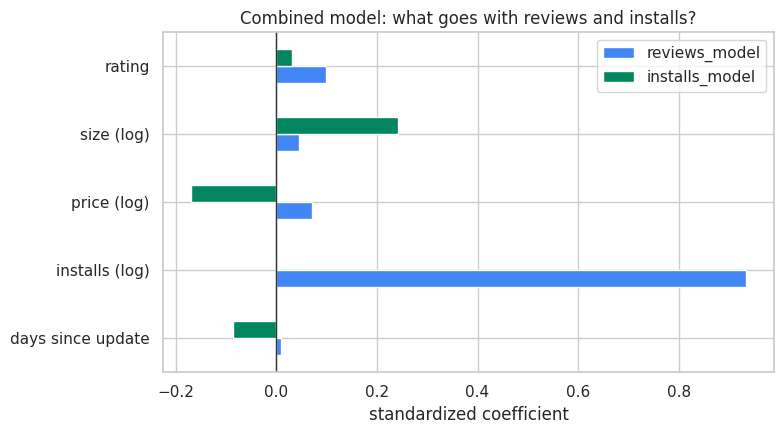


**Answer to RQ8.** (n = 7,026 apps with complete data)

- Category alone: R² = 0.12 for log-reviews. Adding installs: **0.91** (+0.79). Adding rating, price, size and recency: 0.92 (+0.02). Standardized installs coefficient: **0.93**.
- Without installs, category plus the other attributes reach R² = 0.23.
- Predicting installs without reviews: category alone R² = 0.10; with the attributes **0.21**. Largest standardized coefficient: **size (log)** (0.24).
- Descriptive model only; installs are bucketed and unrated or unsized apps are excluded.


In [41]:
model_df = clean_df.copy()
model_df["days_since_update_f"] = model_df["days_since_update"].astype(float)

sample_cols = ["log10_reviews", "log10_installs", "rating", "log10_price1", "log10_size_mb", "days_since_update_f", "category"]
cc = model_df[sample_cols].dropna()
attrs = ["rating", "log10_price1", "log10_size_mb", "days_since_update_f"]

m_cat  = ols_fit(cc, "log10_reviews", [], "category")
m_inst = ols_fit(cc, "log10_reviews", ["log10_installs"], "category")
m_all  = ols_fit(cc, "log10_reviews", ["log10_installs"] + attrs, "category")
m_attr = ols_fit(cc, "log10_reviews", attrs, "category")
m_inst_cat = ols_fit(cc, "log10_installs", [], "category")
m_inst_all = ols_fit(cc, "log10_installs", attrs, "category")

fit_table = pd.DataFrame({
    "model": ["reviews ~ category", "reviews ~ category + installs", "reviews ~ category + installs + attributes",
              "reviews ~ category + attributes (no installs)", "installs ~ category", "installs ~ category + attributes"],
    "R2": [m_cat["r2"], m_inst["r2"], m_all["r2"], m_attr["r2"], m_inst_cat["r2"], m_inst_all["r2"]],
    "n": [m_cat["n"]] * 6})
display(fit_table)

betas = pd.DataFrame({"reviews_model": m_all["coefs"], "installs_model": m_inst_all["coefs"]}).rename(
    index={"log10_installs": "installs (log)", "rating": "rating", "log10_price1": "price (log)",
           "log10_size_mb": "size (log)", "days_since_update_f": "days since update"})
display(betas)

fig, ax = plt.subplots(figsize=(8, 4.5))
betas.plot.barh(ax=ax, color=[BLUE, GREEN])
ax.axvline(0, color="#333", lw=1); ax.set_xlabel("standardized coefficient")
ax.set_title("Combined model: what goes with reviews and installs?")
plt.tight_layout()
plt.savefig(f"{image_path}/12_combined_model.png", dpi=150)
plt.show()

gain_inst = m_inst["r2"] - m_cat["r2"]
gain_attr = m_all["r2"] - m_inst["r2"]
strongest_attr_inst = betas["installs_model"].abs().idxmax()

ANSWERS["RQ8"] = (f"Adding installs lifts R² for reviews from {m_cat['r2']:.2f} to {m_inst['r2']:.2f} (+{gain_inst:.2f}); all other attributes add only "
                  f"+{gain_attr:.2f}. Attributes plus category explain {m_inst_all['r2']:.2f} of install variation (top: {strongest_attr_inst}).")

display(Markdown(f"""
**Answer to RQ8.** (n = {m_all['n']:,} apps with complete data)

- Category alone: R² = {m_cat['r2']:.2f} for log-reviews. Adding installs: **{m_inst['r2']:.2f}** (+{gain_inst:.2f}). Adding rating, price, size and recency: {m_all['r2']:.2f} (+{gain_attr:.2f}). Standardized installs coefficient: **{betas.loc['installs (log)', 'reviews_model']:.2f}**.
- Without installs, category plus the other attributes reach R² = {m_attr['r2']:.2f}.
- Predicting installs without reviews: category alone R² = {m_inst_cat['r2']:.2f}; with the attributes **{m_inst_all['r2']:.2f}**. Largest standardized coefficient: **{strongest_attr_inst}** ({betas.loc[strongest_attr_inst, 'installs_model']:.2f}).
- Descriptive model only; installs are bucketed and unrated or unsized apps are excluded.
"""))

#### Spark confirmation of the category ranking

In [42]:
# same ranking computed in spark with a dense_rank window (names are uppercase here)
try:
    cat_spark = (
        clean_sdf.filter(F.col("rating").isNotNull())
        .groupBy("category")
        .agg(F.count("*").alias("rated_apps"),
             F.round(F.avg("rating"), 3).alias("mean_rating"),
             F.expr("percentile_approx(rating, 0.5)").alias("median_rating_approx"))
        .filter(F.col("rated_apps") >= MIN_N)
        .withColumn("rank_by_mean_rating", F.dense_rank().over(Window.orderBy(F.desc("mean_rating"))))
        .orderBy("rank_by_mean_rating")
    )
    display(to_pandas_safe(cat_spark).head(10))
except Exception as exc:
    print(f"spark confirmation skipped: {type(exc).__name__}: {exc}")

,category,rated_apps,mean_rating,median_rating_approx,rank_by_mean_rating
0,EVENTS,45,4.436,4.500,1
1,ART_AND_DESIGN,59,4.359,4.400,2
2,EDUCATION,106,4.355,4.400,3
3,BOOKS_AND_REFERENCE,169,4.345,4.500,4
4,PERSONALIZATION,298,4.332,4.400,5
5,PARENTING,50,4.300,4.400,6
6,BEAUTY,42,4.279,4.300,7
7,SOCIAL,203,4.247,4.300,8
8,GAME,899,4.245,4.300,9
9,HEALTH_AND_FITNESS,244,4.243,4.500,10


#### Research scorecard

In [43]:
QUESTIONS = {
    "RQ1": "Do apps with more installs get more reviews?",
    "RQ2": "Which categories have the best ratings?",
    "RQ3": "Do paid apps earn higher ratings than free apps?",
    "RQ4": "How does app size relate to installs and ratings?",
    "RQ5": "How does price relate to installs?",
    "RQ6": "How do installs and ratings vary with update recency?",
    "RQ7": "Which content-rating groups and genres dominate or are crowded?",
    "RQ8": "Which relationships survive in a combined model?",
}
effect = {
    "RQ1": strength_label(rho_s), "RQ2": eps2_label(eps2), "RQ3": delta_label(d3_adj),
    "RQ4": strength_label(rho_si[0]), "RQ5": delta_label(d5), "RQ6": strength_label(rho_ri[0]),
    "RQ7": "descriptive",
    "RQ8": "large" if gain_inst > 0.25 else ("moderate" if gain_inst > 0.1 else "small"),
}
scorecard = pd.DataFrame({"RQ": list(QUESTIONS), "question": list(QUESTIONS.values()),
                          "effect size": [effect[k] for k in QUESTIONS],
                          "answer (generated)": [ANSWERS[k] for k in QUESTIONS]})
with pd.option_context("display.max_colwidth", None):
    display(scorecard)
scorecard.to_csv(os.path.join(os.path.dirname(clean_path) or ".", "research_scorecard.csv"), index=False)

,RQ,question,effect size,answer (generated)
0,RQ1,Do apps with more installs get more reviews?,very strong,Very strong positive relationship: Spearman rho = 0.968 (95% CI 0.966 to 0.969); each 10x more installs goes with about 8.2x more reviews (R² = 0.92); positive in 100% of categories.
1,RQ2,Which categories have the best ratings?,small,"Highest median ratings: Events, Books & Reference, Health & Fitness (4.5); lowest: Tools, Maps & Navigation, Dating (4.1). Category explains 2.5% of rating rank variance (small effect)."
2,RQ3,Do paid apps earn higher ratings than free apps?,negligible,Paid apps average +0.10 rating points vs. free (95% CI +0.05 to +0.14); Cliff's delta 0.16 (small); after category adjustment 0.14 (negligible).
3,RQ4,How does app size relate to installs and ratings?,weak,Size vs. installs: Spearman rho = 0.31 (weak positive); 1M+ install share peaks in the 60+ MB band; size vs. rating rho = 0.05.
4,RQ5,How does price relate to installs?,large,"Free apps have a median of 100,000 installs vs. 1,000 for paid (Cliff's delta 0.50, large); among paid apps price vs. installs rho = 0.13."
5,RQ6,How do installs and ratings vary with update recency?,weak,Days since update vs. installs rho = -0.33 (weak); vs. rating rho = -0.18; 78% of 1M+ apps were updated in the last 180 days vs. 49% of <10K apps.
6,RQ7,Which content-rating groups and genres dominate or are crowded?,descriptive,'Everyone' holds 82% of apps; top 5 genres hold 29% of apps (HHI 0.036 vs. 0.021 if even); genre size vs. median installs rho = -0.28.
7,RQ8,Which relationships survive in a combined model?,large,Adding installs lifts R² for reviews from 0.12 to 0.91 (+0.79); all other attributes add only +0.02. Attributes plus category explain 0.21 of install variation (top: size (log)).


In [44]:
# recommendations: each line is printed only when the computed evidence supports it
tier_rate = clean_df[clean_df["installs"] >= 1_000].groupby("install_tier", observed=True)["reviews_per_1k_installs"].median()
recs = {"Developers": [], "Product managers": [], "Investors": []}

recs["Developers"].append("Benchmark your review rate (median reviews per 1,000 installs) against your tier: "
                          + ", ".join(f"{t}: {v:.1f}" for t, v in tier_rate.items()) + ".")
recs["Developers"].append(
    f"Category matters for ratings ({eps2_label(eps2)} effect): best-rated are {', '.join(ct.head(3)['category'])}." if eps2 >= 0.01
    else "Category explains almost none of the variation in ratings.")
if len(crowded):
    recs["Developers"].append(f"Check crowding before entering a genre: {', '.join(crowded['primary_genre'])} are large genres with low typical reach per app.")

recs["Product managers"].append(
    "Charging goes with clearly lower reach: pair a paid model with a free tier or trial." if d5 >= 0.33 else
    "Charging goes with modestly lower reach: test price points." if d5 >= 0.147 else
    "Free and paid apps reach similar audiences here.")
recs["Product managers"].append(
    "Fresher apps have more installs: keep a regular update cadence (direction of cause is uncertain)." if rho_ri[0] <= -0.2 else
    "Update recency has little rank relationship with reach here.")
if abs(rho_si[0]) >= 0.2:
    recs["Product managers"].append(f"Size has a {strength_label(rho_si[0])} link with installs (rho = {rho_si[0]:.2f}); treat it as a proxy for complexity.")
recs["Product managers"].append("Track reviews per install, not just review counts, to separate reach from engagement.")

recs["Investors"].append(f"Review counts are a {strength_label(rho_s)} popularity screen (rho = {rho_s:.2f}); installs are bucketed and the link is correlational, so confirm with other data.")
if gain_attr < 0.02:
    recs["Investors"].append("Once installs are known, rating, price, size and recency add almost nothing to explaining reviews.")

display(Markdown("\n\n".join(f"**{who}**\n" + "\n".join(f"- {line}" for line in lines) for who, lines in recs.items())))

**Developers**
- Benchmark your review rate (median reviews per 1,000 installs) against your tier: <10K: 14.0, 10K-1M: 14.1, 1M+: 20.7.
- Category matters for ratings (small effect): best-rated are Events, Books & Reference, Health & Fitness.
- Check crowding before entering a genre: Business, Medical, Education are large genres with low typical reach per app.

**Product managers**
- Charging goes with clearly lower reach: pair a paid model with a free tier or trial.
- Fresher apps have more installs: keep a regular update cadence (direction of cause is uncertain).
- Size has a weak link with installs (rho = 0.31); treat it as a proxy for complexity.
- Track reviews per install, not just review counts, to separate reach from engagement.

**Investors**
- Review counts are a very strong popularity screen (rho = 0.97); installs are bucketed and the link is correlational, so confirm with other data.
- Once installs are known, rating, price, size and recency add almost nothing to explaining reviews.

### Limitations
- Association, not causation; reviews and installs, price and installs, and updates and installs can influence each other in both directions.
- Installs are bucket lower bounds, which creates rank ties and approximate slopes.
- Ratings exist only for apps that attracted reviews (unrated apps are a much less installed group), so RQ2, RQ3 and RQ6 describe rated apps.
- Reviews and installs are cumulative and app age is not in the data, so older apps are advantaged on both.
- One scraped snapshot of unknown sampling; recency is measured from its newest update date.
- Only the first genre of multi-genre apps is used.
- Many comparisons on ~10k apps: effect sizes, not p-values, carry the conclusions.

## Dashboard

**Data source:** `data/google_play_store_cleaned.csv`. Sort `installs_bucket` by `installs_bucket_rank`; the band fields (`size_band`, `price_band`, `recency_band`, `install_tier`) are text and need a manual sort order in Tableau.

| Page | Visualizations | Question |
|---|---|---|
| 1. Overview | KPI tiles (apps, total installs, median rating, median reviews per 1,000 installs); installs vs. reviews scatter (log axes, trend line) | RQ1 |
| 2. Reviews and Installs | median reviews and review rate by install bucket; outlier table | RQ1 |
| 3. Ratings | median rating by category; free vs. paid rating distribution | RQ2, RQ3 |
| 4. App Traits | size, price and recency bands vs. installs and ratings | RQ4, RQ5, RQ6 |
| 5. Market Structure | genre bubble chart; content-rating bars | RQ7 |

Interactivity: filters for category, type, content rating and install tier; a metric parameter (reviews, rating, review rate) and a minimum-installs parameter; navigation buttons on every page. Colors match the notebook (green installs, blue reviews, red highlights).



### Link to Published Dashboard

<div class='tableauPlaceholder' id='viz1794709635567' style='position: relative'><noscript><a href='#'><img alt='App Downloads and Review Analysis ' src='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;Go&#47;GooglePlaystoreAppAnalysis_17946942766570&#47;Story1&#47;1_rss.png' style='border: none' /></a></noscript><object class='tableauViz'  style='display:none;'><param name='host_url' value='https%3A%2F%2Fpublic.tableau.com%2F' /> <param name='embed_code_version' value='3' /> <param name='site_root' value='' /><param name='name' value='GooglePlaystoreAppAnalysis_17946942766570&#47;Story1' /><param name='tabs' value='no' /><param name='toolbar' value='yes' /><param name='static_image' value='https:&#47;&#47;public.tableau.com&#47;static&#47;images&#47;Go&#47;GooglePlaystoreAppAnalysis_17946942766570&#47;Story1&#47;1.png' /> <param name='animate_transition' value='yes' /><param name='display_static_image' value='yes' /><param name='display_spinner' value='yes' /><param name='display_overlay' value='yes' /><param name='display_count' value='yes' /><param name='language' value='en-US' /><param name='filter' value='publish=yes' /></object></div>                <script type='text/javascript'>                    var divElement = document.getElementById('viz1794709635567');                    var vizElement = divElement.getElementsByTagName('object')[0];                    vizElement.style.width='1016px';vizElement.style.height='991px';                    var scriptElement = document.createElement('script');                    scriptElement.src = 'https://public.tableau.com/javascripts/api/viz_v1.js';                    vizElement.parentNode.insertBefore(scriptElement, vizElement);                </script>

## Conclusion

Results below are from the executed run on 9,659 apps (10,841 raw rows; 1 malformed row and 1,181 repeated app rows removed). Re-check them against the scorecard if the data or cleaning changes.

**Primary question (RQ1).** Installs and reviews have a very strong positive relationship: Spearman rho = 0.968 (bootstrap 95% CI 0.966 to 0.969). Each 10x increase in installs goes with about 8.2x more reviews (log-log slope 0.916, R² = 0.919). It holds in all 33 categories with at least 30 apps (lowest within-category rho 0.871) and without zero-review apps (rho = 0.965). Raw Pearson is only 0.625 because a few blockbuster apps dominate the raw scale.

**Supporting questions**
- **RQ2 (category ratings):** Events, Books & Reference and Health & Fitness have the highest median rating (4.5); Tools, Maps & Navigation and Dating the lowest (4.1 to 4.2). Category explains 2.5% of rating rank variance (small). The top groups have 45 to 244 rated apps, so read them as a tier. Unrated apps (15.1% of listings) are far less installed (Cliff's delta = -0.88).
- **RQ3 (free vs. paid ratings):** paid apps average 4.26 vs. 4.17 for free (Cliff's delta 0.16, small; 0.14, negligible after category adjustment).
- **RQ4 (size):** larger apps tend to have more installs, the opposite of the hypothesis (rho = 0.31, weak). The 1M+ share rises from 13.5% (<5 MB) to 58.0% (60+ MB), and is 73.9% for "Varies with device" apps. Size is unrelated to rating (rho = 0.05).
- **RQ5 (price):** the free vs. paid gap is large: median installs of 100,000 vs. 1,000 (Cliff's delta 0.50). Among paid apps, price level has a negligible relationship with installs (rho = 0.13).
- **RQ6 (recency):** fresher apps have more installs (rho = -0.33, weak); 78% of 1M+ apps were updated in the last 180 days vs. 49% of <10K apps. The link with rating is negligible (rho = -0.18).
- **RQ7 (market structure):** `Everyone` apps are 82% of listings and 70% of installs. The top 5 genres hold 29% of apps (HHI 0.036 vs. 0.021 if even). Larger genres tend to have lower reach per app (rho = -0.28); Business, Medical and Education are large genres with low typical reach.
- **RQ8 (combined model):** adding installs raises R² for log-reviews from 0.12 to 0.91; rating, price, size and recency add only 0.02. For installs, category plus those attributes explain R² = 0.21, with size the largest coefficient.

**Recommendations** are generated in the cell above from these results.

**Future work:** add app age or review velocity, model review counts with a negative binomial regression with category effects, and repeat the analysis on a newer dataset.

## Appendix: AI Usage Log

| # | Prompt used (paste exact text) | AI response (summary) | What I changed or verified |
|---|---|---|---|
| 1 | Asked what the task requires and for a step-by-step plan | Deliverables, grading criteria and a 12-step plan | `[describe]` |
| 2 | Asked for a GitHub README | Portfolio README with placeholders | `[describe]` |
| 3 | Asked for the completed notebook (installs vs. reviews as the main question) | Full CRISP-DM notebook with PySpark cleaning and analysis | The cleaning cell failed with `ModuleNotFoundError: No module named 'pyarrow'` |
| 4 | "the dataset is 4mb pyarrow is causing a lot of errors also enhance the code and enhance the research questions and address the questions and answer them" | Replaced the Python UDF with a native Spark expression, disabled Arrow, replaced `toPandas()` with a `collect()`-based converter, expanded one question into RQ1 to RQ8 with generated answers | Ran the notebook end to end on the 10,841-row file; checked outputs against the data |
| 5 | "udpaet ethsi extensively based on yoru finings above" (with the README draft) | README rewritten around RQ1 to RQ8, methods, troubleshooting and the new repository layout | `[describe]` |
| 6 | Tableau questions: using the cleaned CSV; which charts and dashboards; `MEDIAN([Reviews])`; the `reviews_per_1k_installs` calculated field; KPI canvas setup | Dashboard plan (5 pages, 10 charts), calculated field formulas, KPI tile build steps | `[describe what you built in Tableau]` |
| 7 | "here is how i have decide to rewriet eteh cod enotive i have removed a lot of your commenets and markdown that you had wasnt adding up or didnat have teh required rigor retur eth full updated untitle d notebook" | Completed my lean rewrite; fixed renamed path variables and lowercase environment variable names; restored load assertions and helper tests; removed rating imputation in RQ5; added a mean-difference CI in RQ3 | Compared against my own cells; `[describe]` |
| 8 | "doe steh code meet thsi requiremneet s" (with the grading rubric) | Gap analysis against the rubric: execution-model documentation, `explain()`, persistence and cleanup, BLUF, all-column `describe()`, type-mismatch counts, challenges and fixes | `[describe]` |
| 9 | "retrun teh fully update code with eteh fixes above i will add teh link to teh  dahsbaord after genereate tehe now fully udpadte ntebook" | Implemented those gaps in this notebook | `[describe]` |

In [45]:
# release spark resources (re-run the spark cells from the top if you need Spark again after this)
clean_sdf.unpersist()
raw_sdf.unpersist()
spark.stop()